# Assessment 2: Machine Learning and Real Time Streaming
Student ID: 33602190  
Unit: ITO5202  
Year: 2026

This assessment uses the IBM AML HI-Small dataset from Assessment 1. Part A compares classification models and saves the selected model. Part B uses that model to predict transactions sent through Kafka.

## 0. Environment and configuration
Start Kafka with `bash scripts/start_kafka.sh` in a separate terminal. Open the notebook with `bash scripts/start_notebook.sh`, select Python (assessment2-aml) and run the cells in order.

File paths start from the project folder. The split uses seed 42, and Spark uses UTC for timestamps. Spark downloads the Kafka connector on its first run.

In [1]:
from pathlib import Path
import os
import sys
import platform
from importlib.metadata import version

PROJECT_ROOT = Path.cwd().resolve()
JAVA_HOME = PROJECT_ROOT / ".runtime/jdk-17.0.20.1+1/Contents/Home"
os.environ["JAVA_HOME"] = str(JAVA_HOME)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_SUBMIT_ARGS"] = "--driver-memory 4g pyspark-shell"

SEED = 42
DATA_DIR = PROJECT_ROOT / "data"
MODEL_PATH = PROJECT_ROOT / "models/a2_model"
STREAM_PATH = DATA_DIR / "stream_data.parquet"
DEVELOPMENT_PATH = DATA_DIR / "development_data.parquet"
KAFKA_BOOTSTRAP_SERVERS = "127.0.0.1:9092"
KAFKA_TOPIC = "aml-transactions"
RUN_KAFKA_SMOKE_TEST = True
SPARK_KAFKA_PACKAGE = "org.apache.spark:spark-sql-kafka-0-10_2.12:3.5.7"

print("Python:", platform.python_version())
print("PySpark:", version("pyspark"))
print("Kafka Python client:", version("kafka-python3"))
print("Python executable:", sys.executable)

Python: 3.11.17
PySpark: 3.5.7
Kafka Python client: 3.0.0
Python executable: /Users/a208109/Desktop/assessment2-aml/.venv/bin/python


### Start Spark
Spark runs with four local threads and 4 GB of driver memory. The Kafka connector matches Spark 3.5.7 and Scala 2.12. The Kafka server uses its own Scala 2.13 build.

In [2]:
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder
         .master("local[4]")
         .appName("Assessment2-AML")
         .config("spark.jars.packages", SPARK_KAFKA_PACKAGE)
         .config("spark.jars.ivy", str(PROJECT_ROOT / ".runtime/ivy"))
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
jvm = spark.sparkContext._jvm
java_version = jvm.java.lang.System.getProperty("java.version")
scala_version = jvm.scala.util.Properties.versionNumberString()
print(f"Spark {spark.version}, Java {java_version}, Scala {scala_version}")

:: loading settings :: url = jar:file:/Users/a208109/Desktop/assessment2-aml/.venv/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Spark 3.5.7, Java 17.0.20.1, Scala 2.12.18


### Check Kafka and Structured Streaming
This check sends a sample JSON array through Kafka and reads it with Python and Spark. It removes the temporary topic when finished. Kafka needs to be running at `127.0.0.1:9092`.

Set `RUN_KAFKA_SMOKE_TEST = False` to skip this check when working offline.

In [3]:
from scripts.check_kafka import check_kafka

if RUN_KAFKA_SMOKE_TEST:
    setup_result = check_kafka(spark, PROJECT_ROOT, KAFKA_BOOTSTRAP_SERVERS)
    print(setup_result)
else:
    print("SKIPPED: Kafka connectivity check")

PASS: Python producer and consumer exchanged one JSON array.


PASS: Spark Structured Streaming parsed the same record using the Kafka connector.
{'python_round_trip': 'PASS', 'spark_streaming': 'PASS', 'records': 1}


## Part A: Machine learning
### A1. Load and validate the dataset

The task is binary classification using `is_laundering` as the target. A value of 1 means simulated laundering, and 0 means no laundering. The aim is to identify transactions that may need review.

The data comes from the HI-Small subset of [IBM Transactions for Anti-Money Laundering (AML)](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml), which was approved for Assessment 1. Each row in the transaction file represents a transaction. The account file provides bank and account details.

#### Check the input files
The checksums are compared with those recorded in Assessment 1. The CSV headers are also checked before the columns are renamed.

In [4]:
import csv
import hashlib
import pandas as pd
from IPython.display import display

expected_hashes = {
    "HI-Small_Trans.csv":
        "b19d39f515523373f991b689c07e11e7b0b95c17a2c27a87d91584ae16c5b040",
    "HI-Small_accounts.csv":
        "786808526e33cfc441212dd6fccda7edfc24172149bed59c6ef59b186836b014",
}
expected_headers = {
    "HI-Small_Trans.csv": [
        "Timestamp", "From Bank", "Account", "To Bank", "Account",
        "Amount Received", "Receiving Currency", "Amount Paid",
        "Payment Currency", "Payment Format", "Is Laundering",
    ],
    "HI-Small_accounts.csv": [
        "Bank Name", "Bank ID", "Account Number", "Entity ID", "Entity Name",
    ],
}
file_checks = []
source_hashes = {}
for filename, expected_hash in expected_hashes.items():
    path = DATA_DIR / filename
    with path.open("rb") as file:
        actual_hash = hashlib.file_digest(file, "sha256").hexdigest()
    with path.open(newline="", encoding="utf-8-sig") as file:
        header = next(csv.reader(file))
    source_hashes[filename] = actual_hash
    file_checks.append((filename, actual_hash == expected_hash, header == expected_headers[filename]))
display(pd.DataFrame(file_checks, columns=["File", "Matches Assessment 1 checksum", "Header matches"]))

,File,Matches Assessment 1 checksum,Header matches
0,HI-Small_Trans.csv,True,True
1,HI-Small_accounts.csv,True,True


#### Load the data
Account numbers are kept as strings. The two columns named `Account` are renamed `sender_account` and `receiver_account`. Bank IDs are numeric in both files. Loading stops if a record cannot be parsed. No rows are removed.

The timestamp format is `yyyy/MM/dd HH:mm`. The source does not specify a timezone, so UTC is used consistently without changing the recorded clock times. Amounts use double precision and are interpreted in their own currencies.

In [5]:
from pyspark import StorageLevel
from pyspark.sql.types import (
    StructType, StructField, TimestampType, LongType,
    StringType, DoubleType, IntegerType,
)

transaction_schema = StructType([
    StructField("timestamp", TimestampType(), True),
    StructField("from_bank", LongType(), True),
    StructField("sender_account", StringType(), True),
    StructField("to_bank", LongType(), True),
    StructField("receiver_account", StringType(), True),
    StructField("amount_received", DoubleType(), True),
    StructField("receiving_currency", StringType(), True),
    StructField("amount_paid", DoubleType(), True),
    StructField("payment_currency", StringType(), True),
    StructField("payment_format", StringType(), True),
    StructField("is_laundering", IntegerType(), True),
])
account_schema = StructType([
    StructField("bank_name", StringType(), True),
    StructField("bank_id", LongType(), True),
    StructField("account_number", StringType(), True),
    StructField("entity_id", StringType(), True),
    StructField("entity_name", StringType(), True),
])

transactions = (
    spark.read.schema(transaction_schema)
    .option("header", True).option("enforceSchema", True)
    .option("timestampFormat", "yyyy/MM/dd HH:mm")
    .option("mode", "FAILFAST")
    .csv(str(DATA_DIR / "HI-Small_Trans.csv"))
    .persist(StorageLevel.MEMORY_AND_DISK)
)
accounts = (
    spark.read.schema(account_schema)
    .option("header", True).option("enforceSchema", True)
    .option("mode", "FAILFAST")
    .csv(str(DATA_DIR / "HI-Small_accounts.csv"))
    .persist(StorageLevel.MEMORY_AND_DISK)
)
transaction_count = transactions.count()
account_count = accounts.count()
display(pd.DataFrame([
    ("Transactions", f"{transaction_count:,}", len(transactions.columns)),
    ("Accounts", f"{account_count:,}", len(accounts.columns)),
], columns=["Dataset", "Rows", "Columns"]))
display(pd.DataFrame([
    (name, field.name, field.dataType.simpleString())
    for name, dataframe in [("Transactions", transactions), ("Accounts", accounts)]
    for field in dataframe.schema.fields
], columns=["Dataset", "Field", "Spark type"]))

,Dataset,Rows,Columns
0,Transactions,"5,078,345",11
1,Accounts,"518,581",5


,Dataset,Field,Spark type
0,Transactions,timestamp,timestamp
1,Transactions,from_bank,bigint
2,Transactions,sender_account,string
3,Transactions,to_bank,bigint
4,Transactions,receiver_account,string
5,Transactions,amount_received,double
6,Transactions,receiving_currency,string
7,Transactions,amount_paid,double
8,Transactions,payment_currency,string
9,Transactions,payment_format,string


#### Check missing and invalid values
Check each column for nulls and text columns for blanks. Amounts must be finite and at least zero. Labels must be 0 or 1. The timestamp check also identifies missing dates after parsing.

In [6]:
missing_results = []
for name, dataframe in [("Transactions", transactions), ("Accounts", accounts)]:
    expressions = []
    for field in dataframe.schema.fields:
        missing = F.col(field.name).isNull()
        if isinstance(field.dataType, StringType):
            missing = missing | (F.trim(F.col(field.name)) == "")
        expressions.append(
            F.sum(F.when(missing, 1).otherwise(0)).alias(field.name)
        )
    counts = dataframe.agg(*expressions).first().asDict()
    missing_results.extend((name, column, count) for column, count in counts.items())
display(pd.DataFrame(missing_results, columns=["Dataset", "Field", "Null or blank rows"]))

invalid_checks = {
    "invalid_labels": (
        F.col("is_laundering").isNull() | ~F.col("is_laundering").isin(0, 1)
    ),
}
for column in ["amount_paid", "amount_received"]:
    invalid_checks[f"invalid_{column}"] = (
        F.col(column).isNull() | F.isnan(column)
        | (F.abs(F.col(column)) == float("inf")) | (F.col(column) < 0)
    )
invalid_results = transactions.agg(*[
    F.sum(F.when(condition, 1).otherwise(0)).alias(name)
    for name, condition in invalid_checks.items()
]).first().asDict()
display(pd.DataFrame(invalid_results.items(), columns=["Check", "Invalid rows"]))

,Dataset,Field,Null or blank rows
0,Transactions,timestamp,0
1,Transactions,from_bank,0
2,Transactions,sender_account,0
3,Transactions,to_bank,0
4,Transactions,receiver_account,0
5,Transactions,amount_received,0
6,Transactions,receiving_currency,0
7,Transactions,amount_paid,0
8,Transactions,payment_currency,0
9,Transactions,payment_format,0


,Check,Invalid rows
0,invalid_labels,0
1,invalid_amount_paid,0
2,invalid_amount_received,0


#### Check dates and labels
Compare the date range and label counts with Assessment 1. These checks cover the original files. Model development uses the separate development data created in A2.

In [7]:
# Keep the displayed dates in UTC.
coverage_display = transactions.agg(
    F.date_format(F.min("timestamp"), "yyyy-MM-dd HH:mm").alias("first"),
    F.date_format(F.max("timestamp"), "yyyy-MM-dd HH:mm").alias("last"),
).first()
display(pd.DataFrame([
    (coverage_display["first"], coverage_display["last"],
     spark.conf.get("spark.sql.session.timeZone")),
], columns=["First transaction", "Last transaction", "Processing timezone"]))
label_counts = transactions.groupBy("is_laundering").count().orderBy(
    "is_laundering"
).collect()
display(pd.DataFrame([
    (row.is_laundering, f"{row['count']:,}",
     f"{100 * row['count'] / transaction_count:.4f}%")
    for row in label_counts
], columns=["Label", "Transactions", "Percent"]))

,First transaction,Last transaction,Processing timezone
0,2022-09-01 00:00,2022-09-18 16:18,UTC


,Label,Transactions,Percent
0,0,"5,073,168",99.8981%
1,1,"5,177",0.1019%


#### Check account matches
An account is identified by its bank ID and account number together. Check that this combination is unique, then count transactions whose sender or receiver has no matching account. This helps prevent joins from duplicating or dropping transactions.

In [8]:
duplicate_account_keys = (
    accounts.groupBy("bank_id", "account_number").count()
    .filter(F.col("count") > 1).count()
)
account_keys = accounts.select("bank_id", "account_number")
unmatched_senders = transactions.join(
    account_keys,
    (transactions.from_bank == account_keys.bank_id)
    & (transactions.sender_account == account_keys.account_number),
    "left_anti",
).count()
unmatched_receivers = transactions.join(
    account_keys,
    (transactions.to_bank == account_keys.bank_id)
    & (transactions.receiver_account == account_keys.account_number),
    "left_anti",
).count()
join_checks = [
    ("Duplicate account key groups", duplicate_account_keys),
    ("Transactions without sender account", unmatched_senders),
    ("Transactions without receiver account", unmatched_receivers),
]
display(pd.DataFrame(join_checks, columns=["Check", "Count"]))

,Check,Count
0,Duplicate account key groups,0
1,Transactions without sender account,0
2,Transactions without receiver account,0


#### Check duplicate transactions
The source has no transaction ID. Compare the ten fields other than the label to find repeated transactions and any conflicting labels. Exact duplicates have the same values in all eleven fields. Keep all rows during these checks.

In [9]:
transaction_content_columns = [
    column for column in transactions.columns if column != "is_laundering"
]
content_groups = transactions.groupBy(*transaction_content_columns).agg(
    F.count("*").alias("source_rows"),
    F.countDistinct("is_laundering").alias("label_variants"),
)
duplicate_summary = content_groups.agg(
    F.sum(F.when(F.col("source_rows") > 1, 1).otherwise(0))
     .alias("repeated_content_groups"),
    F.sum(F.when(F.col("source_rows") > 1, F.col("source_rows")).otherwise(0))
     .alias("rows_in_repeated_groups"),
    F.sum(F.col("source_rows") - F.col("label_variants"))
     .alias("exact_duplicate_excess_rows"),
    F.sum(F.when(F.col("label_variants") > 1, 1).otherwise(0))
     .alias("conflicting_label_groups"),
).first().asDict()
display(pd.DataFrame([
    (name.replace("_", " ").capitalize(), f"{count:,}")
    for name, count in duplicate_summary.items()
], columns=["Check", "Count"]))
print("Source rows retained:", f"{transaction_count:,}")

,Check,Count
0,Repeated content groups,9
1,Rows in repeated groups,18
2,Exact duplicate excess rows,9
3,Conflicting label groups,0


Source rows retained: 5,078,345


#### Validation results
The files contain 5,078,345 transactions and 518,581 accounts, matching Assessment 1. There are no missing values or invalid labels. Both amount fields contain finite values of zero or more. The dates run from 1 September 2022 at 00:00 to 18 September 2022 at 16:18, using UTC for processing.

Every sender and receiver matches an account. The combination of bank ID and account number is unique. There are 5,177 transactions labelled as laundering, or 0.1019% of all transactions. This imbalance needs to be considered when evaluating the models.

Nine pairs have identical transaction details and labels. This gives 18 rows in duplicate groups and nine extra duplicate rows. There are no conflicting labels. Without transaction IDs, it is not possible to tell whether these are duplicate entries or separate events with identical details, so all rows are kept. A2 keeps each pair in the same partition. Different transactions involving the same account can still appear in different partitions.

### A2. Split the development and streaming data

The split targets 75% for development and 25% for streaming. This meets the assignment minimums of 70% and 20%. The streaming data is reserved for Part B before fitting any preprocessing or model.

The nine duplicate pairs need to stay together. A SHA-256 key groups transactions using the ten fields other than the label. A hash calculation includes seed 42 as a salt to assign each group to a partition. The resulting percentages are checked because they will not be exactly 75% and 25%.

Within development, seed 43 is used to target 70% training, 15% validation and 15% testing. Duplicate pairs stay together here as well. Training data is used to fit preprocessing and models. Validation data is used to choose the model and prediction threshold. Test data is reserved for the final evaluation. The split mixes transaction dates and can include the same account in different partitions.

#### Add source row IDs
`source_record_id` is the transaction's position in the original CSV, starting at 1 after the header. Identical rows receive different IDs. Each record occupies one line in this file. The counts and contents are checked against A1 after adding the IDs. Keeping the original file order preserves these IDs.

In [10]:
raw_lines = spark.sparkContext.textFile(
    str(DATA_DIR / "HI-Small_Trans.csv"), minPartitions=4
)
indexed_lines = raw_lines.zipWithIndex().filter(lambda item: item[1] > 0)
numbered_lines = spark.createDataFrame(
    indexed_lines.map(lambda item: (item[1], item[0])),
    "source_record_id long, raw_csv string",
)
identified_transactions = (
    numbered_lines.select(
        "source_record_id",
        F.from_csv(
            "raw_csv", transaction_schema.simpleString(),
            {"mode": "FAILFAST", "timestampFormat": "yyyy/MM/dd HH:mm"},
        ).alias("record"),
    )
    .select("source_record_id", "record.*")
    .withColumn(
        "transaction_group_id",
        F.sha2(F.to_json(F.struct(*transaction_content_columns)), 256),
    )
    .persist(StorageLevel.DISK_ONLY)
)
id_summary = identified_transactions.agg(
    F.count("*").alias("rows"),
    F.countDistinct("source_record_id").alias("unique_ids"),
    F.min("source_record_id").alias("first_id"),
    F.max("source_record_id").alias("last_id"),
).first()
content_matches = transactions.exceptAll(
    identified_transactions.select(*transactions.columns)
).limit(1).count() == 0 and id_summary.rows == transaction_count
display(pd.DataFrame([
    ("Source rows", f"{id_summary.rows:,}"),
    ("Unique IDs", f"{id_summary.unique_ids:,}"),
    ("First / last source ID", f"{id_summary.first_id:,} / {id_summary.last_id:,}"),
    ("Original transaction content matches", content_matches),
], columns=["Check", "Result"]))
transactions.unpersist()
accounts.unpersist()

,Check,Result
0,Source rows,"5,078,345"
1,Unique IDs,"5,078,345"
2,First / last source ID,"1 / 5,078,345"
3,Original transaction content matches,True


DataFrame[bank_name: string, bank_id: bigint, account_number: string, entity_id: string, entity_name: string]

#### Assign the partitions
The assignment uses the transaction group key and a fixed salt. It does not use the label or row position. Hash values are mapped to buckets from 0 to 999,999. With seed 42, the first 750,000 buckets go to development. Seed 43 divides development into training, validation and test data.

The row ID, group ID and partition columns are used to check the split. They are excluded from model features.

In [11]:
MODEL_SPLIT_SEED = 43
HASH_BUCKETS = 1_000_000

def hash_bucket(seed):
    return F.pmod(
        F.xxhash64("transaction_group_id", F.lit(seed)),
        F.lit(HASH_BUCKETS),
    )

def assign_partitions(dataframe):
    outer_bucket = hash_bucket(SEED)
    inner_bucket = hash_bucket(MODEL_SPLIT_SEED)
    return (
        dataframe.withColumn(
            "data_partition",
            F.when(outer_bucket < 750_000, "development").otherwise("stream"),
        )
        .withColumn(
            "model_partition",
            F.when(F.col("data_partition") == "stream", "stream")
             .when(inner_bucket < 700_000, "train")
             .when(inner_bucket < 850_000, "validation")
             .otherwise("test"),
        )
    )

partitioned_transactions = assign_partitions(
    identified_transactions
).persist(StorageLevel.DISK_ONLY)
outer_counts = {
    row.data_partition: row["count"]
    for row in partitioned_transactions.groupBy("data_partition").count().collect()
}
display(pd.DataFrame([
    (name, f"{outer_counts[name]:,}",
     f"{100 * outer_counts[name] / transaction_count:.4f}%")
    for name in ["development", "stream"]
], columns=["Partition", "Rows", "Percent of source"]))

,Partition,Rows,Percent of source
0,development,"3,808,651",74.9979%
1,stream,"1,269,694",25.0021%


#### Check the split
Check that every source row appears once and that each transaction group belongs to only one partition. Repeat the assignment after changing the number of Spark partitions to confirm that the result stays the same.

In [12]:
partition_id_count = partitioned_transactions.select(
    "source_record_id"
).distinct().count()
cross_partition_groups = (
    partitioned_transactions.groupBy("transaction_group_id")
    .agg(F.countDistinct("model_partition").alias("partitions"))
    .filter(F.col("partitions") != 1).count()
)
repeated_assignments = assign_partitions(
    identified_transactions.repartition(3)
).select("source_record_id", "data_partition", "model_partition")
assignment_changes = repeated_assignments.exceptAll(
    partitioned_transactions.select(
        "source_record_id", "data_partition", "model_partition"
    )
).limit(1).count()
display(pd.DataFrame([
    ("Complete source-row coverage", f"{partition_id_count:,} unique IDs"),
    ("Content groups crossing partitions", cross_partition_groups),
    ("Assignment changes after repartitioning", assignment_changes),
], columns=["Check", "Result"]))

,Check,Result
0,Complete source-row coverage,"5,078,345 unique IDs"
1,Content groups crossing partitions,0
2,Assignment changes after repartitioning,0


#### Check the development groups
Count the labels in training, validation and test data to confirm that both classes are present. Streaming labels are not used to select features, tune models or evaluate Part A.

In [13]:
development_source = partitioned_transactions.filter(
    F.col("data_partition") == "development"
)
stream_source = partitioned_transactions.filter(F.col("data_partition") == "stream")
model_counts = {
    row.model_partition: row.asDict()
    for row in development_source.groupBy("model_partition").agg(
        F.count("*").alias("rows"),
        F.sum(F.when(F.col("is_laundering") == 0, 1).otherwise(0)).alias("negative"),
        F.sum(F.when(F.col("is_laundering") == 1, 1).otherwise(0)).alias("positive"),
    ).collect()
}
display(pd.DataFrame([
    (name, f"{model_counts[name]['rows']:,}",
     f"{100 * model_counts[name]['rows'] / outer_counts['development']:.4f}%",
     f"{model_counts[name]['negative']:,}", f"{model_counts[name]['positive']:,}")
    for name in ["train", "validation", "test"]
], columns=["Partition", "Rows", "% of development", "Label 0", "Label 1"]))

,Partition,Rows,% of development,Label 0,Label 1
0,train,"2,664,035",69.9469%,"2,661,302","2,733"
1,validation,"572,159",15.0226%,"571,583",576
2,test,"572,457",15.0304%,"571,869",588


#### Save and reload the data
Save development records to `data/development_data.parquet` and streaming records to `data/stream_data.parquet`. Development records include their training, validation or test assignment. Spark creates a folder of Parquet files for each dataset. Running this cell again replaces these generated files.

Reload both datasets and compare their column types, counts and complete rows with the data before saving. Record the checksums, split settings, paths and counts in `data/split_manifest.json`.

In [14]:
development_source.write.mode("overwrite").parquet(str(DEVELOPMENT_PATH))
stream_source.write.mode("overwrite").parquet(str(STREAM_PATH))

development_df = spark.read.parquet(str(DEVELOPMENT_PATH))
stream_df = spark.read.parquet(str(STREAM_PATH))
reload_checks = []
for name, saved, original in [
    ("development", development_df, development_source),
    ("stream", stream_df, stream_source),
]:
    saved_count = saved.count()
    rows_match = saved_count == outer_counts[name] and original.exceptAll(saved).limit(1).count() == 0
    reload_checks.append((name, saved_count, rows_match, saved.dtypes == original.dtypes))
display(pd.DataFrame(reload_checks, columns=["Reloaded dataset", "Rows", "Rows and IDs match", "Types match"]))

train_df = development_df.filter(F.col("model_partition") == "train")
validation_df = development_df.filter(F.col("model_partition") == "validation")
test_df = development_df.filter(F.col("model_partition") == "test")

import json

split_manifest = {
    "source_sha256": source_hashes,
    "source_record_id": "1-based CSV record position, header excluded",
    "group_columns": transaction_content_columns,
    "method": "SHA-256 content key; xxhash64 with seed argument; modulo buckets",
    "outer_seed": SEED,
    "model_seed": MODEL_SPLIT_SEED,
    "hash_buckets": HASH_BUCKETS,
    "outer_development_threshold": 750_000,
    "model_train_validation_thresholds": [700_000, 850_000],
    "outer_counts": outer_counts,
    "development_partitions": model_counts,
    "paths": {
        "development": str(DEVELOPMENT_PATH.relative_to(PROJECT_ROOT)),
        "stream": str(STREAM_PATH.relative_to(PROJECT_ROOT)),
    },
    "checks": {
        "source_rows": transaction_count,
        "unique_source_ids": partition_id_count,
        "cross_partition_groups": cross_partition_groups,
        "assignment_changes": assignment_changes,
        "parquet_exact_match": all(row[2] and row[3] for row in reload_checks),
    },
}
(DATA_DIR / "split_manifest.json").write_text(
    json.dumps(split_manifest, indent=2, sort_keys=True) + "\n"
)
partitioned_transactions.unpersist()
identified_transactions.unpersist()
print("Saved data/split_manifest.json")

,Reloaded dataset,Rows,Rows and IDs match,Types match
0,development,3808651,True,True
1,stream,1269694,True,True


Saved data/split_manifest.json


#### Split results
Development contains 3,808,651 rows, or 74.9979% of the source. Streaming contains 1,269,694 rows, or 25.0021%. All 5,078,345 source rows are preserved, and both shares meet the assignment minimums.

Within development, there are 2,664,035 training rows, 572,159 validation rows and 572,457 test rows. These contain 2,733, 576 and 588 laundering labels respectively. Both classes are present in each group.

No duplicate group crosses a partition boundary. Changing the Spark partitions did not change any assignments. The saved Parquet files match the original assigned rows and column types. Use `train_df` for fitting, `validation_df` for model selection and `test_df` for final batch evaluation. Keep `stream_df` for Part B.

### A3. Explore the training data

#### Reuse of Assessment 1 analysis
The sender entity summary is adapted from section 3.1 of [Assessment 1](https://github.com/tung-lechu/assessment1-aml/blob/94acdaa21b071efc135a1fb4257710b8664f3fd0/assessment1.ipynb). It uses the same bank and account join keys and extracts the entity type from the part of `entity_name` before `#`. Here the join is checked to make sure it keeps every training row and finds an entity type for each sender.

The payment format and currency summary is adapted from section 3.2. The grouping, transaction counts, currency totals and laundering counts are reused. Assessment 1 calculated these over the full source dataset. Here they are recalculated from `train_df`, so the charts and findings describe only the training partition. Validation, test and streaming records are not included in this exploration.

Assessment 1's results provide background, but its percentages and selected Saudi Riyal thresholds are not carried over as new model results or fixed rules. Its rapid onward transfer flag is also excluded: it can flag an earlier transaction using a later payment, which would not be known when the earlier transaction arrives.

The classification baseline, amount distribution and time plots below are added for Assessment 2. The aim is to score new records from this simulated dataset. These results do not demonstrate detection on real transactions or on customers that were absent from training.

The short summary, plot and interpretation structure follows the approach in [Arda Baran Baytar’s Kaggle notebook](https://www.kaggle.com/code/ardabaranbaytar/anti-money-laundering-transaction-analysis-and-ris). The calculations below use our training split. Amount comparisons cover all currencies using each currency’s own distribution.

#### Class balance and baseline
A model that always predicts 0 provides a simple starting point. Its accuracy can be high when almost every record is labelled 0, even though it misses every laundering transaction. Positive precision is reported as zero by convention when there are no positive predictions.

In [15]:
from IPython.display import Markdown

train_df = train_df.persist(StorageLevel.MEMORY_AND_DISK)
training_labels = {
    row.is_laundering: row["count"]
    for row in train_df.groupBy("is_laundering").count().collect()
}
training_count = sum(training_labels.values())
training_positives = training_labels[1]
training_negatives = training_labels[0]
training_rate = training_positives / training_count
baseline_accuracy = training_negatives / training_count
display(pd.DataFrame([
    (0, "No laundering", f"{training_negatives:,}", f"{baseline_accuracy:.4%}"),
    (1, "Simulated laundering", f"{training_positives:,}", f"{training_rate:.4%}"),
], columns=["Label", "Meaning", "Training rows", "Share"]))
display(pd.DataFrame([
    ("Always predict 0", f"{baseline_accuracy:.4%}", "0 (convention)", "0", "0"),
], columns=["Baseline", "Accuracy", "Positive precision", "Recall", "F1"]))
display(pd.DataFrame([
    (f"{training_negatives:,}", 0, f"{training_positives:,}", 0),
], columns=["True negatives", "False positives", "False negatives", "True positives"]))
display(Markdown(
    f"The training data contains {training_positives:,} laundering records "
    f"out of {training_count:,} transactions ({training_rate:.4%}). "
    "Assessment 1 recorded 5,177 positives in the full dataset, or 0.1019%. "
    f"The always-zero baseline reaches {baseline_accuracy:.4%} accuracy but "
    f"misses all {training_positives:,} positive records. Model comparison "
    "therefore needs positive-class precision, recall and F1, together with "
    "PR-AUC, rather than accuracy alone. These baseline figures describe "
    "training data; validation and test scores will be calculated separately."
))

,Label,Meaning,Training rows,Share
0,0,No laundering,"2,661,302",99.8974%
1,1,Simulated laundering,"2,733",0.1026%


,Baseline,Accuracy,Positive precision,Recall,F1
0,Always predict 0,99.8974%,0 (convention),0,0


,True negatives,False positives,False negatives,True positives
0,"2,661,302",0,"2,733",0


The training data contains 2,733 laundering records out of 2,664,035 transactions (0.1026%). Assessment 1 recorded 5,177 positives in the full dataset, or 0.1019%. The always-zero baseline reaches 99.8974% accuracy but misses all 2,733 positive records. Model comparison therefore needs positive-class precision, recall and F1, together with PR-AUC, rather than accuracy alone. These baseline figures describe training data; validation and test scores will be calculated separately.

#### Plotting libraries
Spark calculates the summaries. Pandas, Matplotlib and Seaborn display them.

In [16]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#### Sender entity types
Reuse the bank and account join from Assessment 1 to compare entity types. The accounts file is a static lookup. Entity type would need to be available during streaming if selected as a model feature.

,entity_type,transactions,positives,rate
0,Corporation,738357,922,0.1249
1,Partnership,934890,953,0.1019
2,Sole Proprietorship,939808,840,0.0894
3,Individual,2263,2,0.0884
4,Country,48452,16,0.0330
5,Direct,265,0,0.0000


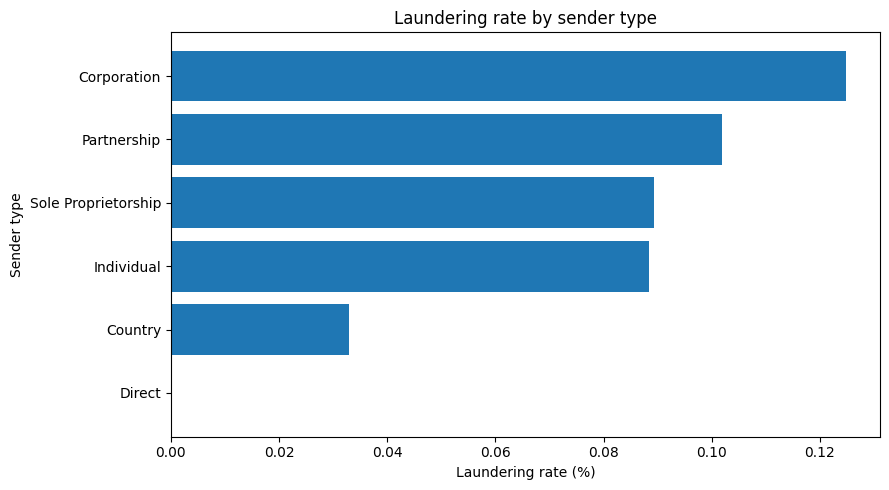

In [17]:
sender_types = accounts.select(
    F.col("bank_id").alias("from_bank"), F.col("account_number").alias("sender_account"),
    F.trim(F.regexp_replace("entity_name", r"\s*#.*$", "")).alias("entity_type"),
)
sender_training = train_df.join(sender_types, ["from_bank", "sender_account"], "left")
entity_risk = sender_training.groupBy("entity_type").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).toPandas()
display(entity_risk.round(4))
plot_data = entity_risk.sort_values("rate")

plt.figure(figsize=(9, 5))
plt.barh(plot_data["entity_type"], plot_data["rate"])
plt.title("Laundering rate by sender type")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Sender type")
plt.tight_layout()
plt.show()

Corporation has the highest observed rate, with 922 positives among 738,357 transactions. Partnership has the largest positive count, at 953. Rate and count answer different questions. Individual has only two positive records, so its rate has limited support.

#### Payment formats
Reuse Assessment 1’s payment format and currency grouping. The first table shows the ten combinations with the most training transactions. Amounts are totalled only within a currency. The chart compares label rates across formats.

,payment_format,payment_currency,transactions,amount_paid,positives
0,Cheque,US Dollar,371601,1.355933e+11,68
1,Credit Card,US Dollar,265802,8.674700e+08,46
2,Cheque,Euro,231310,7.873304e+10,56
3,Credit Card,Euro,165811,4.582520e+08,32
4,ACH,US Dollar,125951,1.195821e+11,841
5,Cash,US Dollar,98389,4.949174e+10,22
6,Reinvestment,US Dollar,97720,2.412700e+10,0
7,Bitcoin,Bitcoin,76898,1.494323e+06,31
8,ACH,Euro,73827,5.551849e+10,631
9,Reinvestment,Euro,61039,1.377238e+10,0


,payment_format,transactions,positives,rate
0,ACH,315374,2340,0.7420
1,Bitcoin,76937,31,0.0403
2,Cash,257554,60,0.0233
3,Cheque,977805,192,0.0196
4,Credit Card,694028,110,0.0158
5,Wire,90238,0,0.0000
6,Reinvestment,252099,0,0.0000


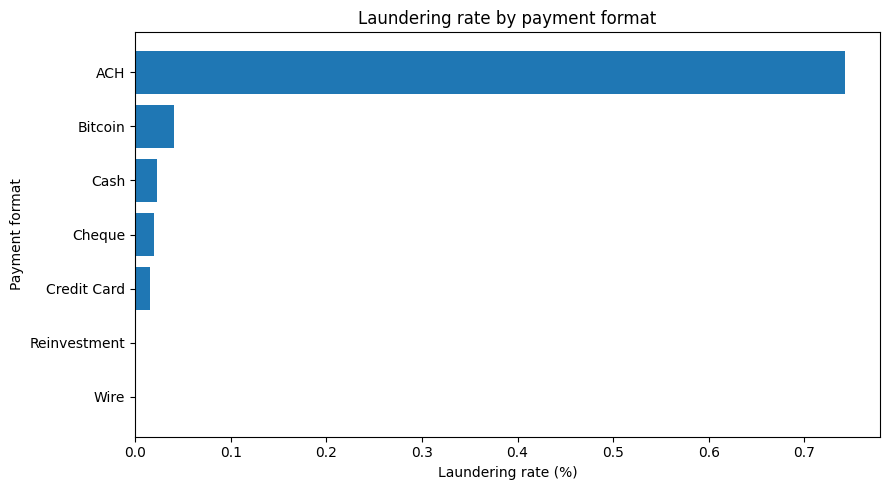

In [18]:
payment_summary = train_df.groupBy("payment_format", "payment_currency").agg(
    F.count("*").alias("transactions"), F.sum("amount_paid").alias("amount_paid"),
    F.sum("is_laundering").alias("positives"),
)
display(payment_summary.orderBy(F.desc("transactions")).limit(10).toPandas().round(2))
format_risk = train_df.groupBy("payment_format").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).toPandas()
display(format_risk.round(4))
plot_data = format_risk.sort_values("rate")

plt.figure(figsize=(9, 5))
plt.barh(plot_data["payment_format"], plot_data["rate"])
plt.title("Laundering rate by payment format")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Payment format")
plt.tight_layout()
plt.show()

ACH contains 2,340 of the 2,733 training positives. Its rate is much higher than the other formats, making payment format a useful candidate feature. Zero observed positives for a format do not establish that future payments are safe.

#### Payment currencies
Compare both the number and proportion of laundering labels. Currency names identify units of payment and are not reliable evidence of where a transaction took place.

,payment_currency,transactions,positives,rate
0,Saudi Riyal,46940,191,0.4069
1,Euro,612713,732,0.1195
2,Yen,81330,86,0.1057
3,Australian Dollar,71778,71,0.0989
4,US Dollar,993890,977,0.0983
5,Swiss Franc,123155,111,0.0901
6,Canadian Dollar,73212,65,0.0888
7,Yuan,112238,99,0.0882
8,Rupee,100047,88,0.0880
9,Ruble,81242,71,0.0874


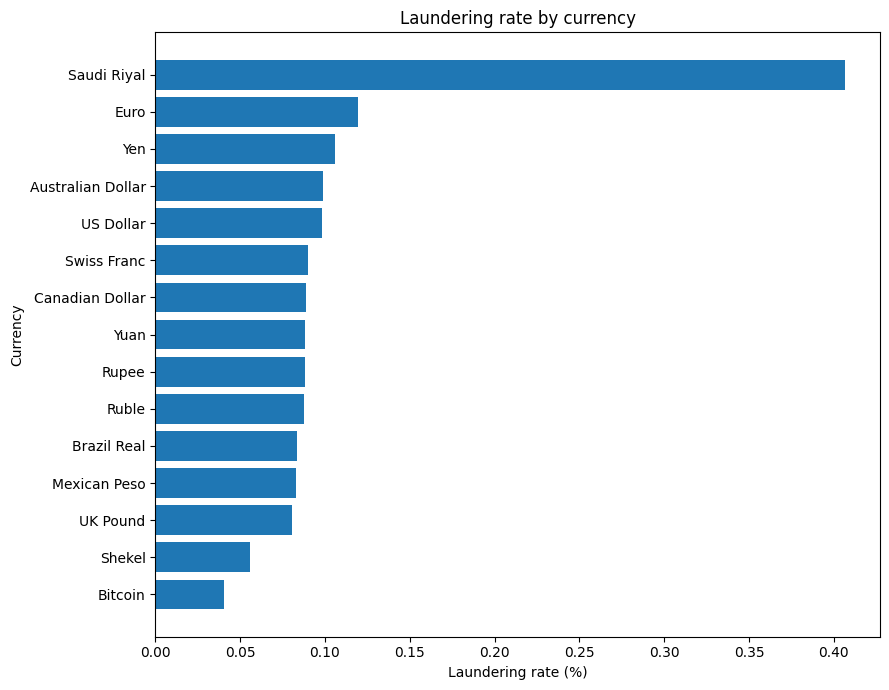

In [19]:
currency_risk = train_df.groupBy("payment_currency").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).toPandas()
display(currency_risk.round(4))
plot_data = currency_risk.sort_values("rate")

plt.figure(figsize=(9, 7))
plt.barh(plot_data["payment_currency"], plot_data["rate"])
plt.title("Laundering rate by currency")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Currency")
plt.tight_layout()
plt.show()

Saudi Riyal has the highest rate at 0.4069%, with 191 positives. USD and Euro have the largest positive counts, at 977 and 732. A high rate is different from a large number of cases; both matter when deciding which patterns deserve attention.

#### Does the payment format pattern change across currencies?
Compare ACH with all other formats within each currency. This gives an overview with two bars per currency; the next heatmap keeps all formats separate. Rates use the transaction count of each currency and format group, rather than the size of the whole dataset.

In [20]:
format_currency_risk = train_df.withColumn(
    "format_group", F.when(F.col("payment_format") == "ACH", "ACH").otherwise("Other formats")
).groupBy("payment_currency", "format_group").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).toPandas()
currencies = currency_risk["payment_currency"].tolist()
display(format_currency_risk.sort_values("rate", ascending=False).head(6).round(3))

,payment_currency,format_group,transactions,positives,rate
15,Saudi Riyal,ACH,5191,186,3.583
13,Euro,ACH,73827,631,0.855
20,Yen,ACH,9590,78,0.813
0,Australian Dollar,ACH,7825,62,0.792
12,Swiss Franc,ACH,13647,95,0.696
9,Mexican Peso,ACH,6418,44,0.686


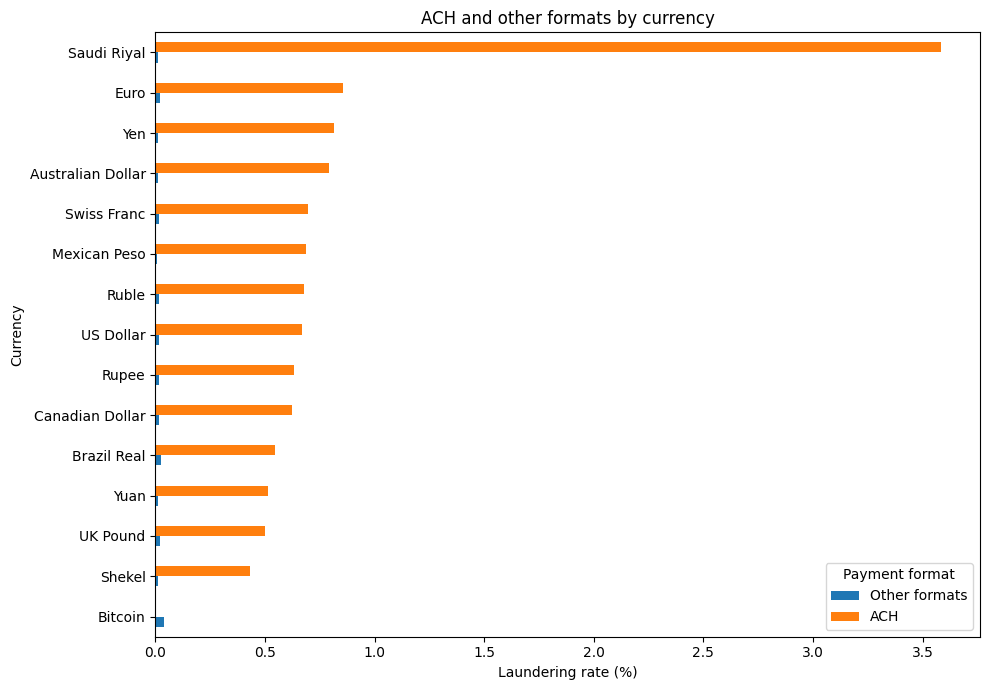

In [21]:
plot_data = format_currency_risk.pivot(index="payment_currency", columns="format_group", values="rate")
plot_data = plot_data[["Other formats", "ACH"]].sort_values("ACH")

plot_data.plot.barh(figsize=(10, 7))
plt.title("ACH and other formats by currency")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Currency")
plt.legend(title="Payment format")
plt.tight_layout()
plt.show()

Saudi Riyal ACH payments have a 3.58% rate, compared with 0.67% for USD ACH and 0.85% for Euro ACH. ACH accounts for 186 of the 191 Saudi Riyal positives. This shows why format and currency should be considered together. The Bitcoin-currency ACH group has only 18 transactions and no positives, so that comparison is particularly limited. These results do not support copying Assessment 1’s Saudi Riyal threshold into the model.

#### Payment format and currency heatmap
Each cell shows the laundering percentage within a format and currency. Blank cells have fewer than 1,000 records, so their rates are hidden. The count table shows the size of each group.

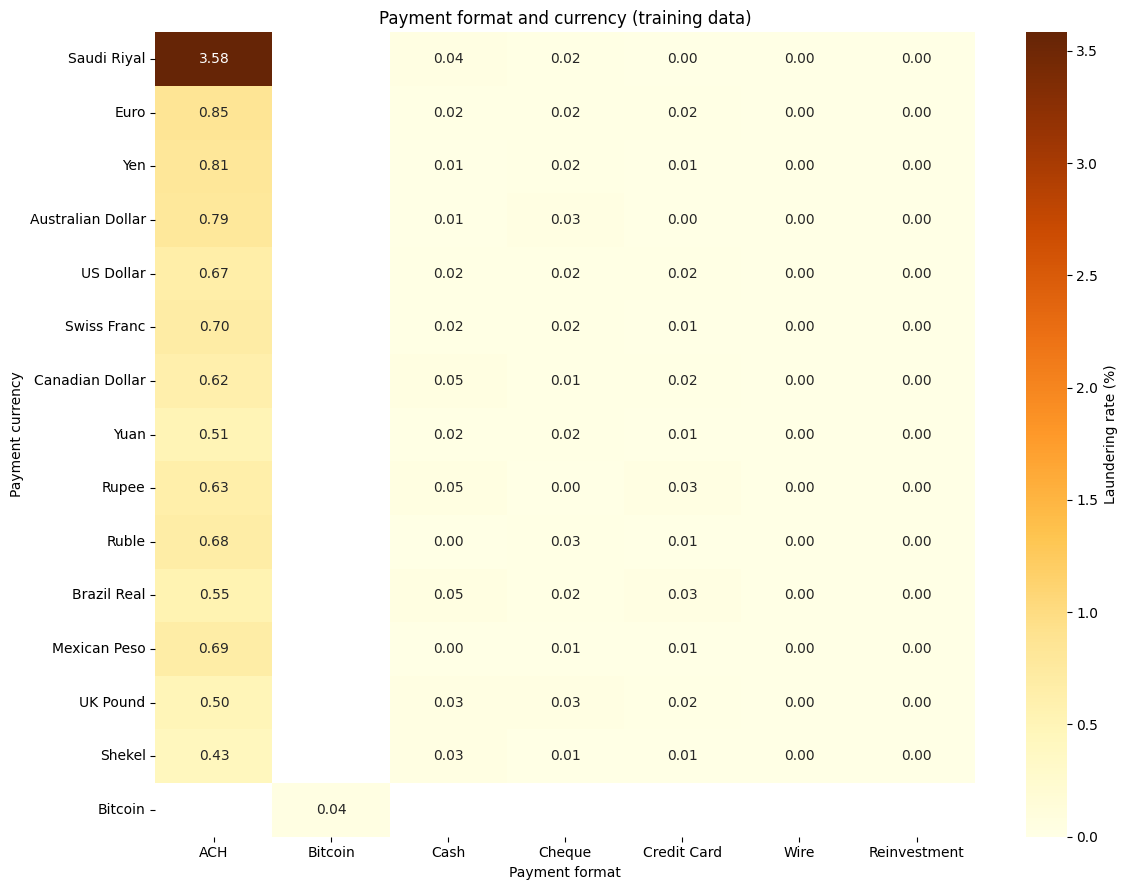

payment_format,ACH,Bitcoin,Cash,Cheque,Credit Card,Wire,Reinvestment
payment_currency,,,,,,,
Saudi Riyal,5191,0,4972,18130,12573,1853,4221
Euro,73827,18,59696,231310,165811,21012,61039
Yen,9590,0,8362,31066,21592,2900,7820
Australian Dollar,7825,0,7189,27842,19682,2542,6698
US Dollar,125951,10,98389,371601,265802,34417,97720
Swiss Franc,13647,4,12545,47290,33158,4388,12123
Canadian Dollar,8696,0,7344,27907,19784,2515,6966
Yuan,16995,1,10773,40891,29151,3807,10620
Rupee,11728,6,10270,38632,26326,3541,9544


In [22]:
payment_grid = payment_summary.withColumn("rate", 100 * F.col("positives") / F.col("transactions")).toPandas()
format_order = format_risk["payment_format"].tolist()
rate_grid = payment_grid.pivot(index="payment_currency", columns="payment_format", values="rate").reindex(index=currencies, columns=format_order)
count_grid = payment_grid.pivot(index="payment_currency", columns="payment_format", values="transactions").reindex_like(rate_grid).fillna(0)
plt.figure(figsize=(12, 9))
sns.heatmap(rate_grid, mask=count_grid < 1000, annot=True, fmt=".2f", cmap="YlOrBr",
            vmin=0, cbar_kws={"label": "Laundering rate (%)"})
plt.title("Payment format and currency (training data)")
plt.xlabel("Payment format")
plt.ylabel("Payment currency")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
display(count_grid.astype(int))

ACH has the highest displayed rate in each fiat currency, reaching 3.58% for Saudi Riyal. Other formats have much lower rates. Blank cells lack enough records for this comparison. A displayed 0.00 may be a small rate rounded to two decimals.

#### Amount box plots across currencies
Compare the two labels within each currency. Boxes show the middle 50% of amounts; whiskers mark the 5th and 95th percentiles. Spark estimates these percentiles from all training records.

The log scale makes the wide amount range readable. Each panel has its own scale, so amounts should not be compared between currencies. The table gives group counts and medians.

In [23]:
amount_quantiles = train_df.groupBy("payment_currency", "is_laundering").agg(
    F.count("*").alias("transactions"),
    F.percentile_approx("amount_paid", [0.05, 0.25, 0.5, 0.75, 0.95], 10000).alias("quantiles"),
).toPandas()
amount_quantiles["median"] = amount_quantiles.quantiles.map(lambda q: q[2])
display(amount_quantiles[["payment_currency", "is_laundering", "transactions", "median"]].sort_values(["payment_currency", "is_laundering"]))

,payment_currency,is_laundering,transactions,median
9,Australian Dollar,0,71707,1289.440000
13,Australian Dollar,1,71,5598.370000
0,Bitcoin,0,76893,0.071712
29,Bitcoin,1,31,0.225070
28,Brazil Real,0,37088,5340.480000
22,Brazil Real,1,31,22129.520000
8,Canadian Dollar,0,73147,1149.460000
18,Canadian Dollar,1,65,7755.910000
1,Euro,0,611981,742.790000
25,Euro,1,732,5313.330000


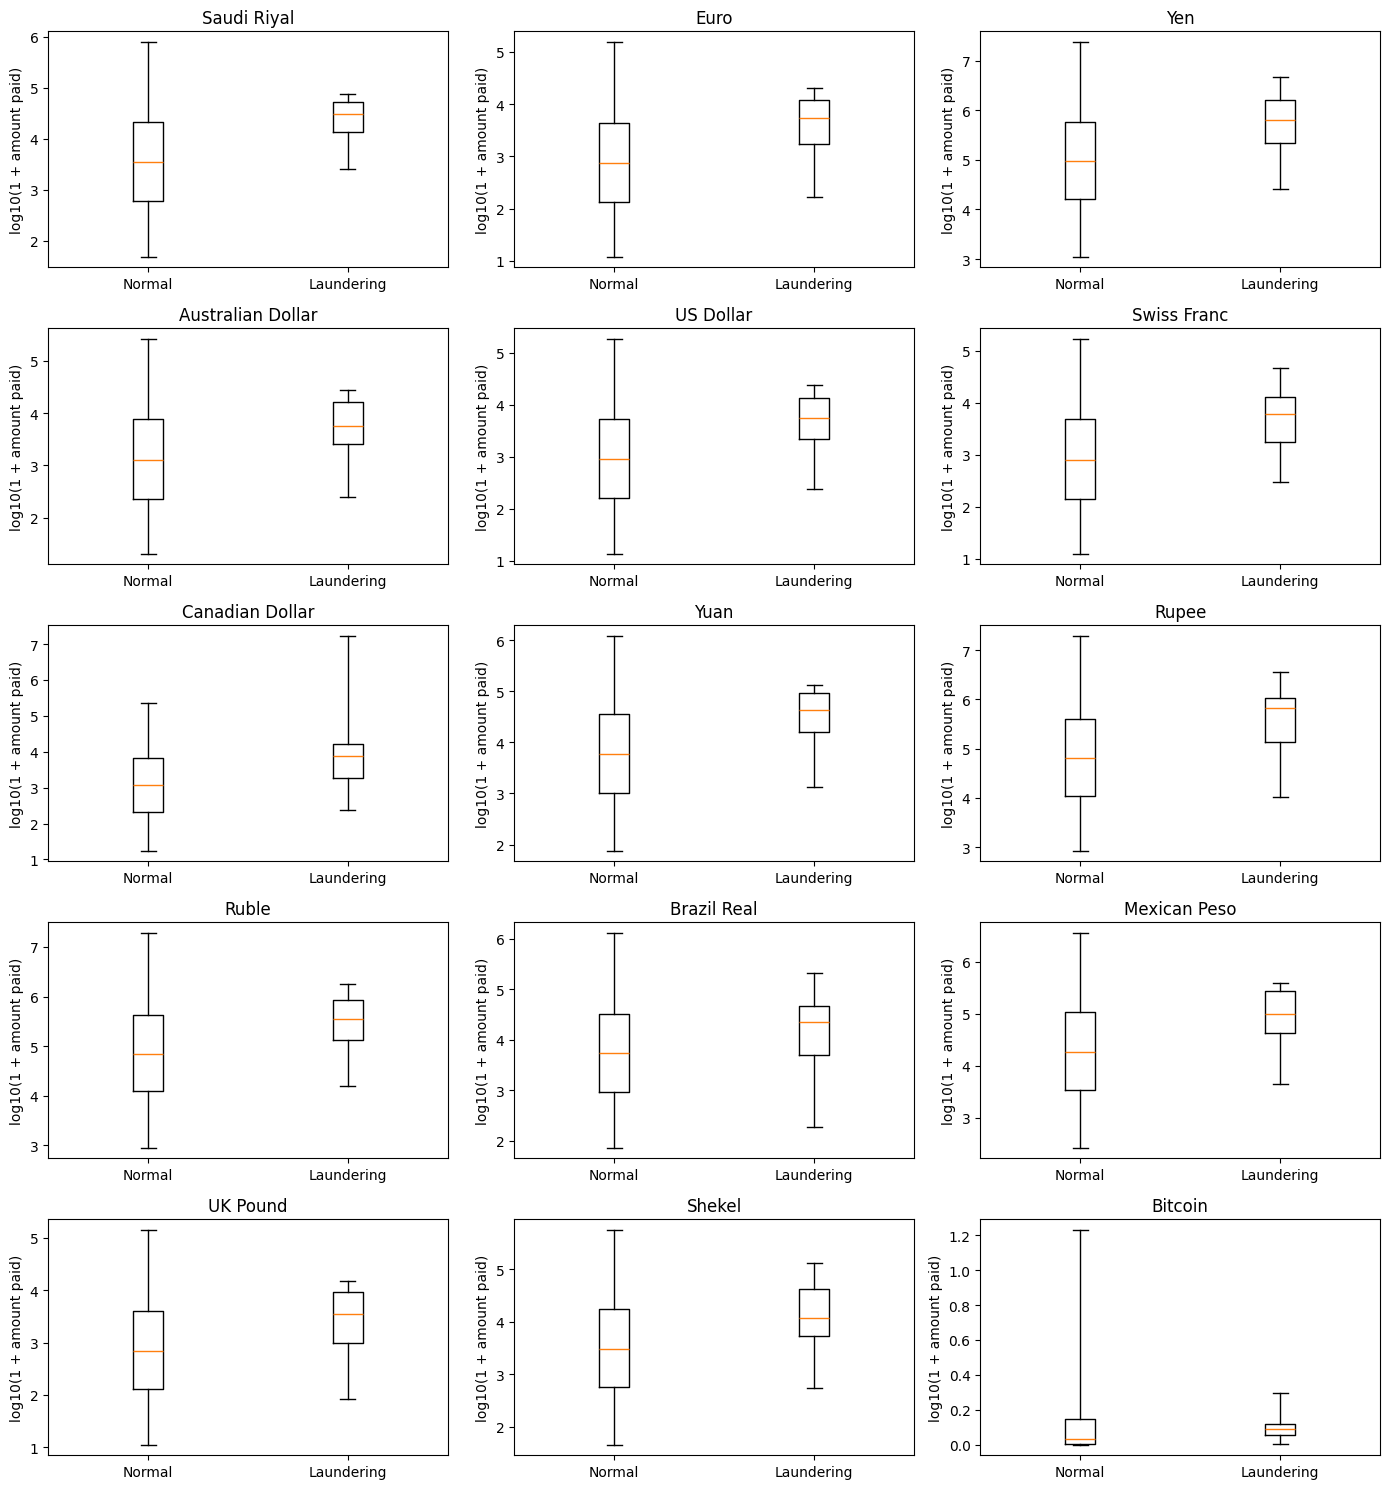

In [24]:
fig, axes = plt.subplots(5, 3, figsize=(14, 15))
for ax, currency in zip(axes.flat, currencies):
    rows = amount_quantiles[amount_quantiles["payment_currency"] == currency].sort_values("is_laundering")
    boxes = []
    for quantiles in rows["quantiles"]:
        low, q1, median, q3, high = np.log10(1 + np.array(quantiles))
        boxes.append(dict(whislo=low, q1=q1, med=median, q3=q3, whishi=high))
    ax.bxp(boxes, showfliers=False)
    ax.set_title(currency)
    ax.set_xticks([1, 2], ["Normal", "Laundering"])
    ax.set_ylabel("log10(1 + amount paid)")
plt.tight_layout()
plt.show()

The laundering median is higher than the normal median in all 15 currencies. For example, the approximate medians are USD 5,517.96 versus 899.49, Euro 5,313.33 versus 742.79, and Saudi Riyal 30,855.39 versus 3,455.32. These are comparisons within each currency; the numbers should not be compared as equivalent monetary values across currencies.

The boxes and whiskers still overlap, and the positive groups contain only 31 to 977 observations. Higher typical amounts therefore provide context rather than a clean boundary between labels. Different payment-format mixes can also contribute to these pooled differences.

#### Amount histograms for three contrasting currencies
Box plots summarise spread; histograms show the shape of each distribution. USD and Euro have the most positive records, while Saudi Riyal has the highest overall label rate. These three panels provide a closer view of those groups, alongside the all-currency box plots above.

Each class is normalised separately to 100%, so its shape remains visible despite the class imbalance. The plots use every training record in the selected currencies and bins of width 0.25 on log10(1 + amount paid). They do not show the relative sizes of the two classes.

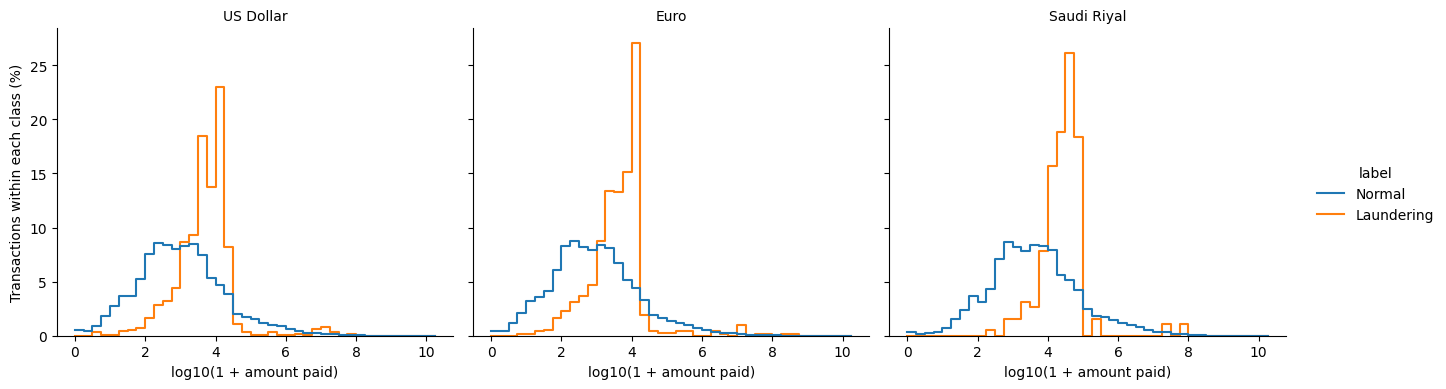

In [25]:
focus_currencies = ["US Dollar", "Euro", "Saudi Riyal"]
amount_bins = train_df.filter(F.col("payment_currency").isin(focus_currencies)).groupBy(
    "payment_currency", "is_laundering",
    F.floor(F.log10(F.col("amount_paid") + 1) * 4).cast("int").alias("bin"),
).count().toPandas()
histogram_data = amount_bins.assign(
    log_amount=(amount_bins["bin"] + 0.5) / 4,
    label=amount_bins["is_laundering"].map({0: "Normal", 1: "Laundering"}),
)
histogram = sns.displot(
    data=histogram_data, x="log_amount", weights="count", hue="label",
    hue_order=["Normal", "Laundering"], col="payment_currency", col_order=focus_currencies,
    binwidth=0.25, binrange=(0, (amount_bins["bin"].max() + 1) / 4),
    stat="percent", common_norm=False, element="step", fill=False, height=4, aspect=1.1,
)
histogram.set_axis_labels("log10(1 + amount paid)", "Transactions within each class (%)")
histogram.set_titles("{col_name}")
plt.show()

The positive distributions are more concentrated than the normal distributions in these three currencies. Their tallest bins are around 10,000 to 17,800 for USD and Euro, and 31,600 to 56,200 for Saudi Riyal. Those bins contain approximately 23%, 27% and 26% of the respective positive classes.

Normal payments also occur throughout those ranges and extend into large upper tails. The histograms explain why a shift in the median does not make amount alone a reliable classifier. The curves show within-class percentages, not the probability that an amount is laundering.

#### Relative amount and laundering across all currencies
Is a relatively large payment more likely to carry a laundering label? Calculate the median, 90th and 99th percentiles separately for each payment currency, then put each transaction into one of four amount bands. A yen payment is compared with other yen payments, and a Saudi Riyal payment with other Saudi Riyal payments. No exchange-rate conversion or addition of different currency amounts is needed.

All 15 currencies contribute. Percentiles are approximate, and tied amounts mean the groups need not contain exactly 50%, 40%, 9% and 1% of records. The combined rates still reflect the mix of currencies and formats, so they are descriptive rather than an isolated effect of amount. The cutoffs are calculated from training data only and are used here for exploration.

,amount_band,transactions,positives,rate
0,1. Up to median,1331885,384,0.0288
1,2. Median to 90th percentile,1065597,2237,0.2099
2,3. 90th to 99th percentile,239751,58,0.0242
3,4. Above 99th percentile,26802,54,0.2015


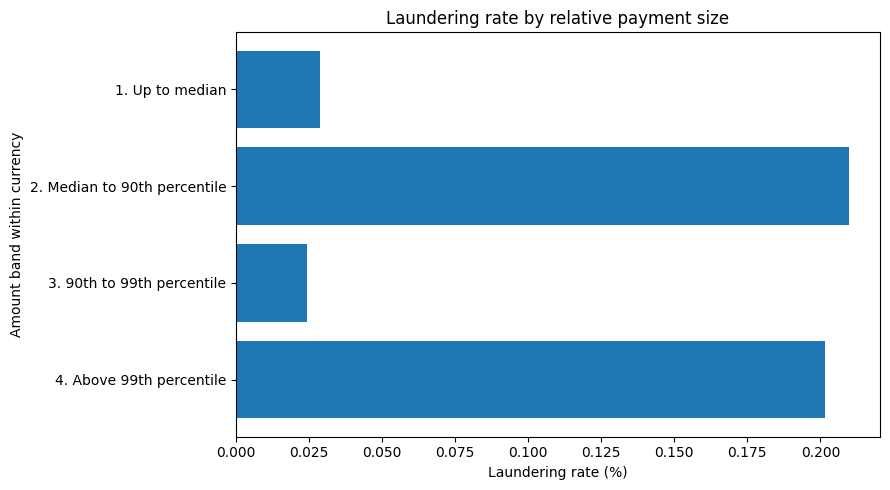

In [26]:
amount_cutoffs = train_df.groupBy("payment_currency").agg(
    F.percentile_approx("amount_paid", [0.5, 0.9, 0.99], 10000).alias("cutoffs")
)
amount_bands = train_df.join(amount_cutoffs, "payment_currency").withColumn(
    "amount_band",
    F.when(F.col("amount_paid") <= F.col("cutoffs")[0], "1. Up to median")
     .when(F.col("amount_paid") <= F.col("cutoffs")[1], "2. Median to 90th percentile")
     .when(F.col("amount_paid") <= F.col("cutoffs")[2], "3. 90th to 99th percentile")
     .otherwise("4. Above 99th percentile"),
)
amount_risk = amount_bands.groupBy("amount_band").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy("amount_band").toPandas()
display(amount_risk.round(4))
plot_data = amount_risk.sort_values("amount_band", ascending=False)

plt.figure(figsize=(9, 5))
plt.barh(plot_data["amount_band"], plot_data["rate"])
plt.title("Laundering rate by relative payment size")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Amount band within currency")
plt.tight_layout()
plt.show()

The median-to-90th-percentile band has the highest observed rate, 0.2099%, and contains 2,237 of the 2,733 positives, or 81.85%. Payments above the 99th percentile have a similar rate of 0.2015%, but only 54 positives. The intervening 90th-to-99th-percentile band has a much lower rate of 0.0242%.

The relationship is not a steady increase in laundering rate as relative amount grows. A single large-payment threshold would miss much of the observed pattern. Relative size is useful context alongside payment format and currency, but these pooled rates do not prove an independent effect of amount.

#### Paid and received amount check
Do the two amount columns provide different information? Compare them across all training records where both amounts use the same currency. Differences between amounts in different currencies would mix units.

In [27]:
same_currency = train_df.filter(F.col("payment_currency") == F.col("receiving_currency"))
paired_amount_summary = same_currency.groupBy("payment_currency").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    F.sum(F.when(F.col("amount_paid") != F.col("amount_received"), 1).otherwise(0)).alias("unequal_amounts"),
).toPandas()
display(paired_amount_summary.sort_values("transactions", ascending=False))

,payment_currency,transactions,positives,unequal_amounts
0,US Dollar,973630,977,0
3,Euro,605100,732,0
12,Swiss Franc,122933,111,0
4,Yuan,106850,99,0
13,Shekel,100759,56,0
10,Rupee,99419,88,0
1,UK Pound,93219,76,0
14,Ruble,81076,71,0
5,Yen,80497,86,0
7,Bitcoin,76898,31,0


Paid and received amounts are identical in all 2,626,282 same-currency training transactions, across all 15 currencies. A scatter plot of this pair would collapse onto one line and add little information.

For these records, amount received duplicates amount paid. Cross-currency amounts were excluded because their difference would mix units. This supports avoiding a raw paid-minus-received feature across the whole dataset.

#### Does payment format change the amount relationship?
Compare amount bands within each payment format. The bands use each currency's own percentiles and include all training records. The table gives the counts behind the rates; the credit card group above the 99th percentile has only one record.

,payment_format,amount_band,transactions,positives,rate
16,ACH,1. Up to median,148124,198,0.134
0,ACH,2. Median to 90th percentile,127414,2059,1.616
20,ACH,3. 90th to 99th percentile,35081,35,0.100
1,ACH,4. Above 99th percentile,4755,48,1.009
18,Bitcoin,1. Up to median,38457,7,0.018
25,Bitcoin,2. Median to 90th percentile,30776,24,0.078
24,Bitcoin,3. 90th to 99th percentile,6927,0,0.000
27,Bitcoin,4. Above 99th percentile,777,0,0.000
11,Cash,1. Up to median,128559,34,0.026
2,Cash,2. Median to 90th percentile,86918,19,0.022


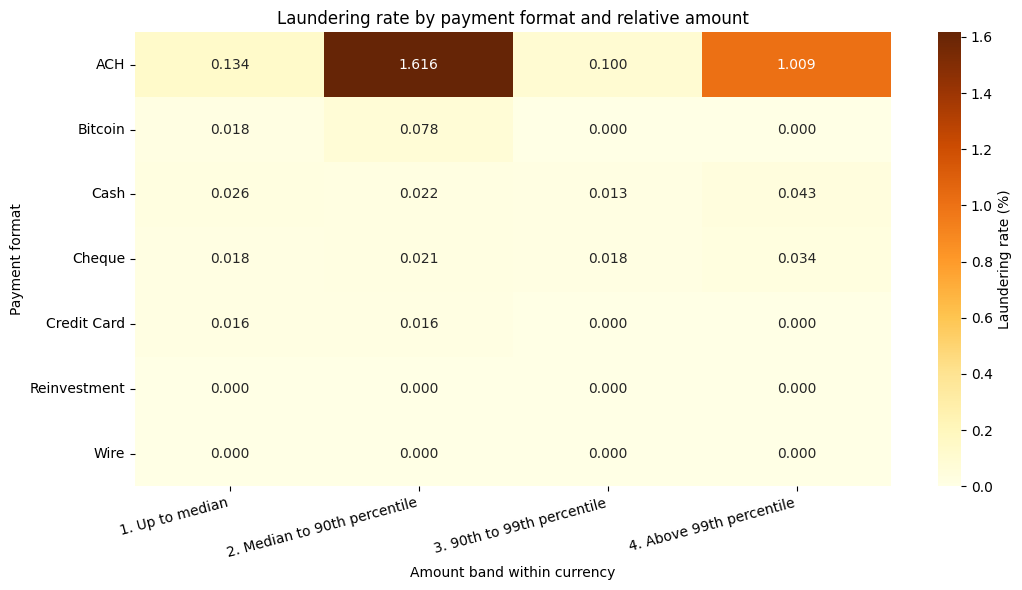

In [28]:
amount_format = amount_bands.groupBy("payment_format", "amount_band").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).toPandas()
band_order = sorted(amount_format.amount_band.unique())
format_order = ["ACH", "Bitcoin", "Cash", "Cheque", "Credit Card", "Reinvestment", "Wire"]
display(amount_format.sort_values(["payment_format", "amount_band"]).round(3))
rate_grid = amount_format.pivot(index="payment_format", columns="amount_band", values="rate").reindex(format_order)[band_order]

plt.figure(figsize=(11, 6))
sns.heatmap(rate_grid, annot=True, fmt=".3f", cmap="YlOrBr", vmin=0,
            cbar_kws={"label": "Laundering rate (%)"})
plt.title("Laundering rate by payment format and relative amount")
plt.xlabel("Amount band within currency")
plt.ylabel("Payment format")
plt.xticks(rotation=15, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

The middle amount band is mainly an ACH pattern. ACH payments between the median and 90th percentile contain 2,059 positives among 127,414 transactions, a rate of 1.616%. This group accounts for only 4.78% of training transactions but 75.34% of all positive labels. It also supplies 92.04% of the positives in the pooled middle band.

Within ACH, this rate is about 12.1 times the rate below the median (0.134%). It drops to 0.100% in the 90th-to-99th band before rising to 1.009% above the 99th percentile. Cash, cheque and credit card payments do not show the same middle-band peak. Transaction size therefore needs to be considered together with payment format; a rule that only looks for the largest payments would miss most of the labelled cases.

These are descriptive training results. Even in the ACH middle band, 98.384% of transactions have label 0. The concentration suggests a useful feature relationship, not a sufficient detection rule or an independently measured causal effect.

#### Does the ACH pattern hold across currencies?
Compare ACH payments between each currency's median and 90th percentile. These cutoffs use all training payments in that currency. The table shows whether a high rate represents many cases or a small group.

,payment_currency,transactions,positives,rate
10,Saudi Riyal,2068,170,8.221
2,Euro,29975,552,1.842
4,Yen,3640,67,1.841
6,Australian Dollar,3180,54,1.698
11,Mexican Peso,2500,41,1.640
14,Swiss Franc,5527,82,1.484
12,Ruble,3452,51,1.477
0,US Dollar,51871,750,1.446
9,Rupee,4568,61,1.335
1,Brazil Real,1693,21,1.240


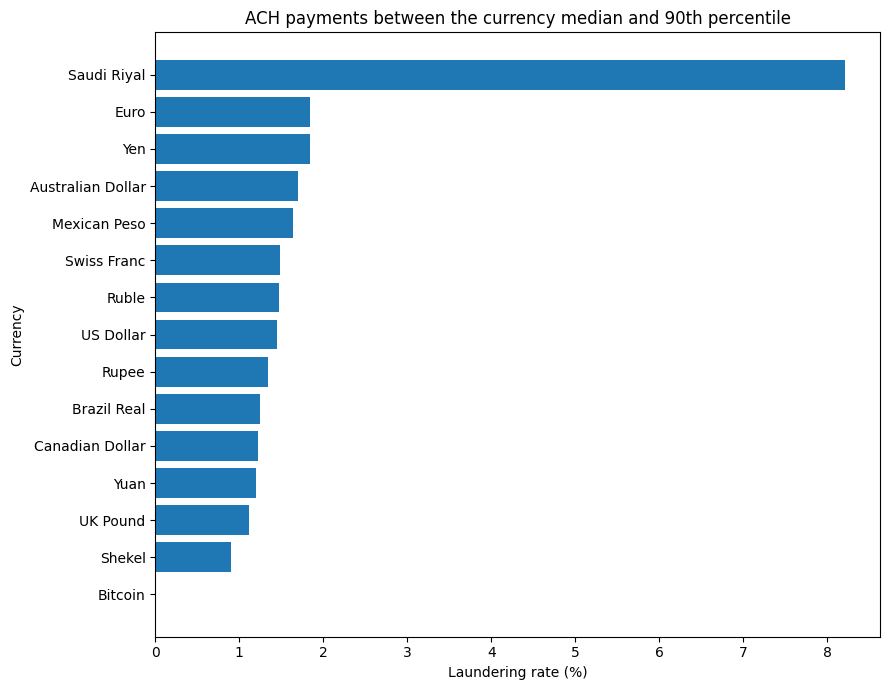

In [29]:
ach_middle = amount_bands.filter(
    (F.col("payment_format") == "ACH") & (F.col("amount_band") == band_order[1])
).groupBy("payment_currency").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).toPandas().sort_values("rate", ascending=False)
display(ach_middle.round(3))
plot_data = ach_middle.sort_values("rate")

plt.figure(figsize=(9, 7))
plt.barh(plot_data["payment_currency"], plot_data["rate"])
plt.title("ACH payments between the currency median and 90th percentile")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Currency")
plt.tight_layout()
plt.show()

Saudi Riyal stands out even within the same payment format and relative amount band: 170 of 2,068 transactions are positive, or 8.22%. Euro has 552 of 29,975 (1.84%) and USD has 750 of 51,871 (1.45%). Saudi Riyal has the highest observed rate, while USD contributes the largest number of cases in this group.

This narrows the earlier Saudi Riyal finding to a specific combination of currency, format and relative size. It is not explained solely by comparing ACH in one currency with other formats in another. However, the bands cover different monetary ranges and may still differ in entities, banks and timing. The single Bitcoin-denominated ACH record in this band provides too little evidence for a rate comparison.

The modelling implication is to evaluate amount, currency and payment format together. These rates and labels are not predictor columns, and any apparent benefit must be checked on validation data before drawing conclusions about model performance.

#### Transaction timing
Use the original transaction timestamp with the notebook’s UTC convention. Hourly and daily summaries cover all training currencies. Daily counts help show whether a high rate is based on very few records.

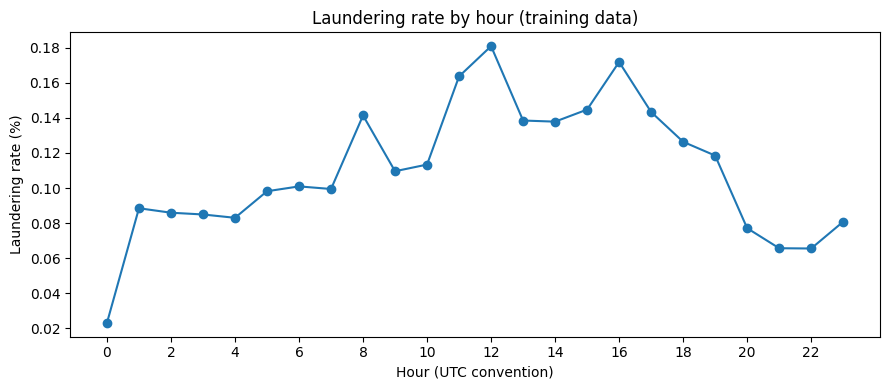

In [30]:
hour_risk = train_df.groupBy(F.hour("timestamp").alias("hour")).agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy("hour").toPandas()
day_risk = train_df.groupBy(F.date_format("timestamp", "yyyy-MM-dd").alias("date")).agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy("date").toPandas()
plt.figure(figsize=(9, 4))
plt.plot(hour_risk["hour"], hour_risk["rate"], marker="o")
plt.xticks(range(0, 24, 2))
plt.xlabel("Hour (UTC convention)")
plt.ylabel("Laundering rate (%)")
plt.title("Laundering rate by hour (training data)")
plt.tight_layout()
plt.show()

,date,transactions,positives,rate
0,2022-09-01,584378,182,0.031
1,2022-09-02,396284,242,0.061
2,2022-09-03,108861,196,0.180
3,2022-09-04,109264,214,0.196
4,2022-09-05,253487,242,0.095
5,2022-09-06,252434,284,0.113
6,2022-09-07,253643,245,0.097
7,2022-09-08,253058,281,0.111
8,2022-09-09,342588,257,0.075
9,2022-09-10,109437,224,0.205


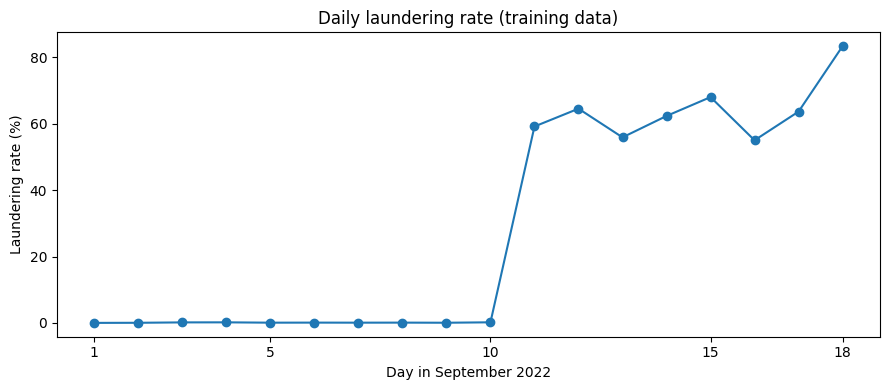

In [31]:
display(day_risk.round(3))
plt.figure(figsize=(9, 4))
plt.plot(pd.to_datetime(day_risk["date"]).dt.day, day_risk["rate"], marker="o")
plt.xticks([1, 5, 10, 15, 18])
plt.xlabel("Day in September 2022")
plt.ylabel("Laundering rate (%)")
plt.title("Daily laundering rate (training data)")
plt.tight_layout()
plt.show()

After 10 September, only 601 training records remain, including 366 positives. This produces a 60.90% rate, but describes just 0.0226% of the training transactions. The final date has five positives among six records. The daily plot therefore reflects a substantial change in the dataset, not evidence of a recurring seasonal trend.

Absolute calendar date will be excluded from the initial feature set because it could identify this sparse tail. The 333,223 records at midnight also deserve caution. Time features need validation, and our random split does not establish performance on a later period.

#### Weekday and hour together
This view includes all training transactions from 1 to 18 September. The table shows the counts behind the five highest rates. With little activity after 10 September, these results cannot establish a stable weekly pattern.

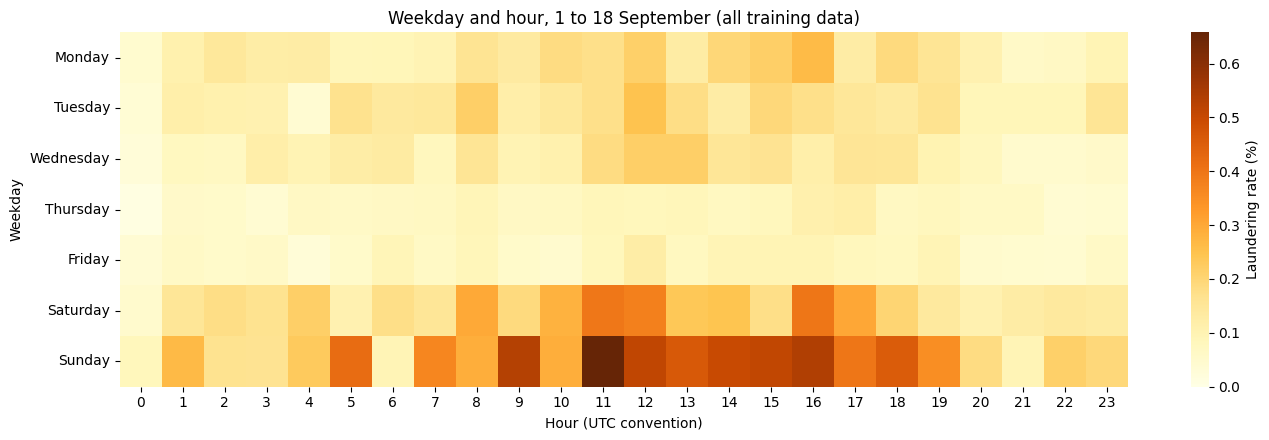

,weekday,hour,transactions,positives,rate
90,Sunday,11,4256,28,0.657895
65,Sunday,16,4267,23,0.539020
93,Sunday,9,4332,23,0.530933
14,Sunday,12,4099,21,0.512320
42,Sunday,15,4321,22,0.509141


In [32]:
time_grid = train_df.groupBy(
    F.date_format("timestamp", "EEEE").alias("weekday"), F.hour("timestamp").alias("hour"),
).agg(F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
      (100 * F.avg("is_laundering")).alias("rate")).toPandas()
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
hourly_rates = time_grid.pivot(index="weekday", columns="hour", values="rate").reindex(index=days, columns=range(24))
plt.figure(figsize=(14, 4.5))
sns.heatmap(hourly_rates, cmap="YlOrBr", vmin=0,
            cbar_kws={"label": "Laundering rate (%)"})
plt.title("Weekday and hour, 1 to 18 September (all training data)")
plt.xlabel("Hour (UTC convention)")
plt.ylabel("Weekday")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
display(time_grid.sort_values("rate", ascending=False).head(5))

Sunday has the highest overall rate at 0.3151%, followed by Saturday at 0.1956%. Sunday at 11:00 is the highest hourly group, with 28 positives among 4,256 transactions (0.6579%).

The final eight dates add only 601 transactions but 366 positives. This uneven coverage affects the pattern, so weekday and hour still need validation.

#### Bank and currency relationships
Do payments within the same bank have a different label rate from payments between banks? Does changing currency show a different pattern? Both comparisons include all training currencies. Bank and currency differences do not by themselves identify an international payment.

,bank_relationship,transactions,positives,rate
0,Different banks,2301360,2675,0.1162
1,Same bank,362675,58,0.0160


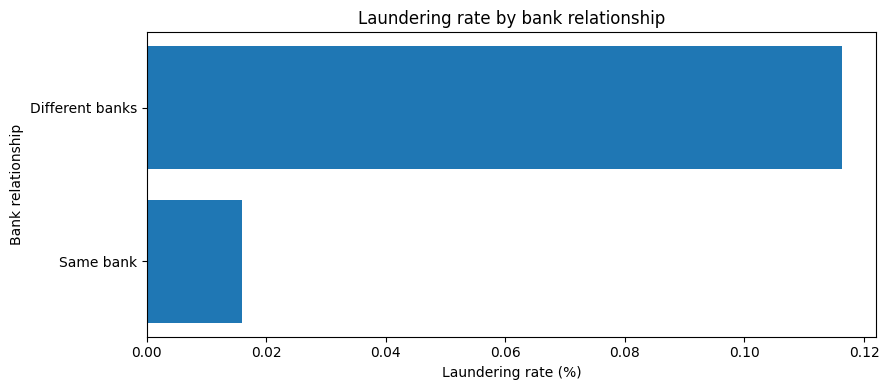

In [33]:
relationship_df = train_df.withColumn(
    "bank_relationship", F.when(F.col("from_bank") == F.col("to_bank"), "Same bank").otherwise("Different banks")
).withColumn(
    "currency_relationship", F.when(F.col("payment_currency") == F.col("receiving_currency"),
                                     "Same currency").otherwise("Different currencies")
)
bank_risk = relationship_df.groupBy("bank_relationship").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).toPandas()
display(bank_risk.round(4))
plot_data = bank_risk.sort_values("rate")

plt.figure(figsize=(9, 4))
plt.barh(plot_data["bank_relationship"], plot_data["rate"])
plt.title("Laundering rate by bank relationship")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Bank relationship")
plt.tight_layout()
plt.show()

Different-bank payments have a 0.1162% label rate, compared with 0.0160% for same-bank payments, about 7.3 times as high. They also contain 2,675 of the 2,733 positives. This supports testing a same-bank indicator, while recognising that other transaction characteristics may explain some of the difference.

,currency_relationship,transactions,positives,rate
0,Same currency,2626282,2733,0.1041
1,Different currencies,37753,0,0.0000


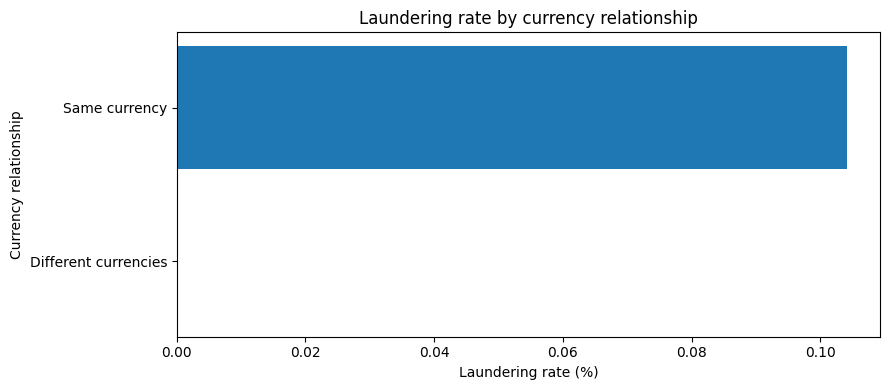

,bank_relationship,currency_relationship,transactions,positives
0,Different banks,Same currency,2301360,2675
1,Same bank,Different currencies,37753,0
2,Same bank,Same currency,324922,58


In [34]:
currency_change_risk = relationship_df.groupBy("currency_relationship").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).toPandas()
display(currency_change_risk.round(4))
plot_data = currency_change_risk.sort_values("rate")

plt.figure(figsize=(9, 4))
plt.barh(plot_data["currency_relationship"], plot_data["rate"])
plt.title("Laundering rate by currency relationship")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Currency relationship")
plt.tight_layout()
plt.show()
relationship_joint = relationship_df.groupBy("bank_relationship", "currency_relationship").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives")
).orderBy("bank_relationship", "currency_relationship").toPandas()
display(relationship_joint)

All 37,753 currency-changing payments have label 0 and occur within the same bank. This could reflect the synthetic data generation process and should not become an automatic safe-payment rule. The joint table also shows that bank and currency relationships are not independent in this dataset.

#### Transaction history
Compare earlier interactions, transaction gaps and amounts relative to a receiver's recent average across all training dates. ACH is also shown separately because it contains most positive labels.

Accounts use bank ID and account number together. Only earlier timestamps count; simultaneous payments cannot use one another. These [Spark windows](https://spark.apache.org/docs/3.5.7/api/python/reference/pyspark.sql/api/pyspark.sql.Window.rangeBetween.html) use training records without their labels. The random split means this is partial account history.

In [35]:
from pyspark.sql import Window

def add_history(data):
    data = data.withColumn("event_second", F.col("timestamp").cast("long"))
    previous_event = F.when(F.col("model_partition") == "train", F.col("event_second"))
    previous_amount = F.when(F.col("model_partition") == "train", F.col("amount_received"))

    pair_window = Window.partitionBy(
        "from_bank", "sender_account", "to_bank", "receiver_account"
    ).orderBy("event_second").rangeBetween(Window.unboundedPreceding, -1)
    sender_window = Window.partitionBy("from_bank", "sender_account").orderBy(
        "event_second"
    ).rangeBetween(Window.unboundedPreceding, -1)
    receiver_window = Window.partitionBy("to_bank", "receiver_account").orderBy(
        "event_second"
    ).rangeBetween(Window.unboundedPreceding, -1)
    amount_window = Window.partitionBy("to_bank", "receiver_account", "receiving_currency").orderBy(
        "event_second"
    ).rangeBetween(-86400, -1)

    data = data.withColumn("prior_pair_count", F.count(previous_event).over(pair_window))
    data = data.withColumn(
        "sender_gap_hours", (F.col("event_second") - F.max(previous_event).over(sender_window)) / 3600
    ).withColumn(
        "receiver_gap_hours", (F.col("event_second") - F.max(previous_event).over(receiver_window)) / 3600
    )
    data = data.withColumn("receiver_previous_24h", F.count(previous_event).over(amount_window))
    data = data.withColumn("receiver_mean_24h", F.avg(previous_amount).over(amount_window))
    return data.withColumn(
        "receiver_amount_ratio",
        F.when(F.col("receiver_mean_24h") > 0, F.col("amount_received") / F.col("receiver_mean_24h")),
    )

history = add_history(train_df).persist(StorageLevel.MEMORY_AND_DISK)
history_check = history.agg(F.count("*").alias("rows"), F.sum("is_laundering").alias("positives")).first()

Rates use all transactions in each group as the denominator. Missing history is shown separately.

In [36]:
def history_summary(records, column, order):
    summary = records.groupBy(column).agg(
        F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
        F.sum(F.when(F.col("payment_format") == "ACH", 1).otherwise(0)).alias("ach_transactions"),
        F.sum(F.when(F.col("payment_format") == "ACH", F.col("is_laundering")).otherwise(0)).alias("ach_positives"),
    ).toPandas().set_index(column)
    summary = summary.reindex([group for group in order if group in summary.index])
    summary["rate"] = 100 * summary["positives"] / summary["transactions"]
    summary["ach_rate"] = 100 * summary["ach_positives"] / summary["ach_transactions"]
    return summary.rename_axis("group")

#### Previous interactions between accounts
Count earlier payments from the same sender to the same receiver. Zero identifies the first observed interaction. The model will use the count rather than the chart bands.

,transactions,positives,ach_transactions,ach_positives,rate,ach_rate
group,,,,,,
0: first observed,738739,2312,106676,2213,0.313,2.075
1,340951,120,32689,61,0.035,0.187
2 to 4,639323,150,59181,47,0.023,0.079
5 to 9,653793,117,69358,15,0.018,0.022
10 or more,291229,34,47470,4,0.012,0.008


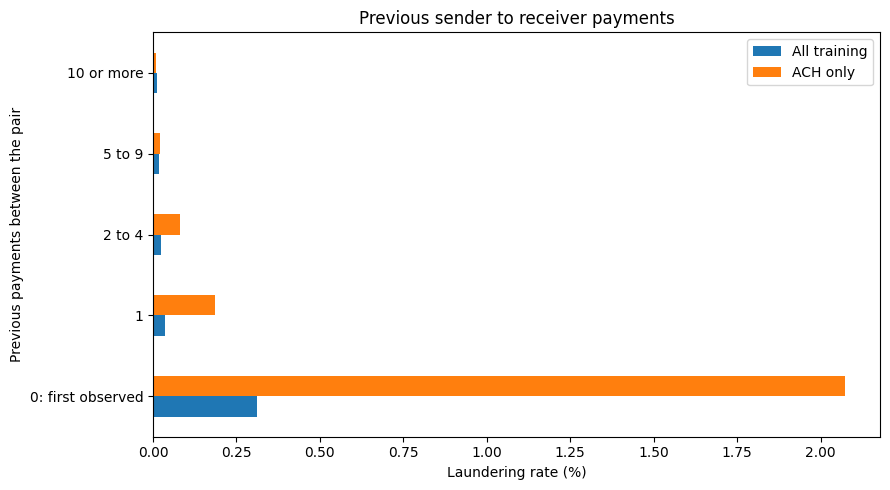

In [37]:
pair_order = ["0: first observed", "1", "2 to 4", "5 to 9", "10 or more"]
pair_records = history.withColumn(
    "pair_band", F.when(F.col("prior_pair_count") == 0, pair_order[0])
    .when(F.col("prior_pair_count") == 1, pair_order[1])
    .when(F.col("prior_pair_count") <= 4, pair_order[2])
    .when(F.col("prior_pair_count") <= 9, pair_order[3]).otherwise(pair_order[4])
)
pair_summary = history_summary(pair_records, "pair_band", pair_order)
display(pair_summary.round(3))
plot_data = pair_summary[["rate", "ach_rate"]].rename(columns={"rate": "All training", "ach_rate": "ACH only"})
plot_data.plot.barh(figsize=(9, 5))
plt.title("Previous sender to receiver payments")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Previous payments between the pair")
plt.tight_layout()
plt.show()

First observed interactions contain 84.60% of positives but only 27.73% of transactions. Within ACH, their rate is 2.075% (2,213/106,676), compared with 0.061% for established pairs. Most still have label 0, and an older relationship may exist outside this sample.

#### Time since the previous transaction
Measure hours since the sender's last outgoing payment and the receiver's last incoming payment. Both use earlier history across currencies. Keep missing history separate from a short gap.

transactions  positives  ach_transactions  \
Direction         Gap                                                           
Sender outgoing   No earlier event        385263        484             49240   
                  Up to 1 hour            959426        448            102673   
                  1 to 24 hours           935618        855             97596   
                  Over 24 hours           383728        946             65865   
Receiver incoming No earlier event        352901        281             26324   
                  Up to 1 hour            775247        394            129220   
                  1 to 24 hours           900718       1031             92245   
                  Over 24 hours           635169       1027             67585   

                                    ach_positives   rate  ach_rate  
Direction         Gap                                               
Sender outgoing   No earlier event            473  0.126     0.961  
                  Up to 1 hour                 94  0.047     0.092  
                  1 to 24 hours               849  0.091     0.870  
                  Over 24 hours               924  0.247     1.403  
Receiver incoming No earlier event            249  0.080     0.946  
                  Up to 1 hour                281  0.051     0.217  
                  1 to 24 hours               891  0.114     0.966  
                  Over 24 hours               919  0.162     1.360

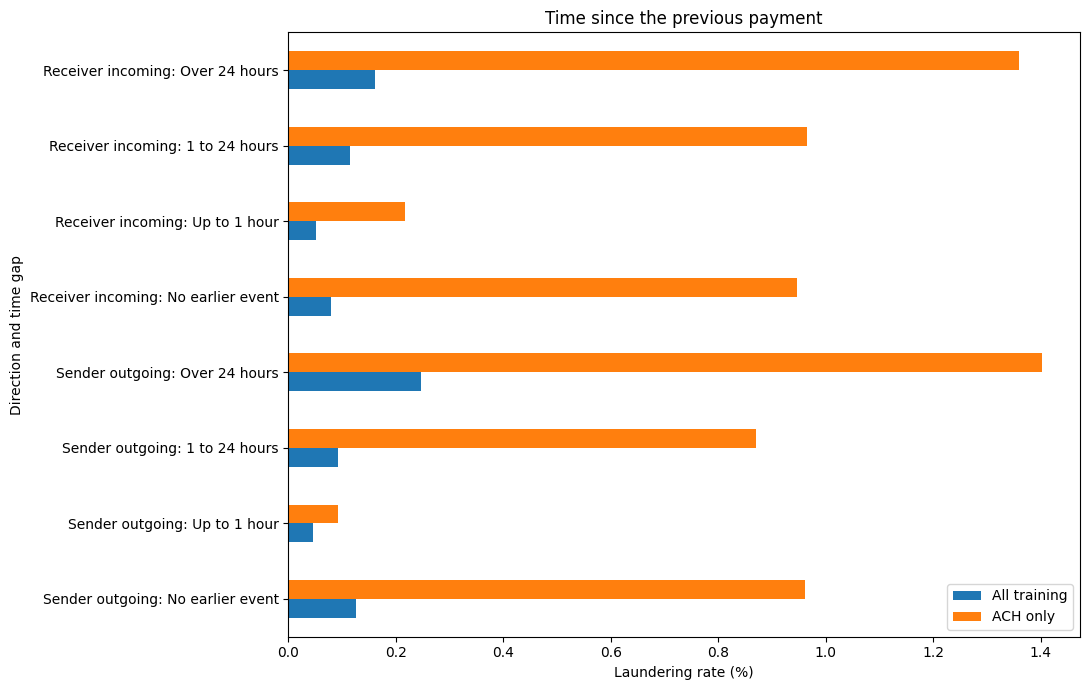

In [38]:
gap_order = ["No earlier event", "Up to 1 hour", "1 to 24 hours", "Over 24 hours"]
gap_summaries = {}
for column, name in [("sender_gap_hours", "Sender outgoing"), ("receiver_gap_hours", "Receiver incoming")]:
    gap_records = history.withColumn(
        "gap_band", F.when(F.col(column).isNull(), gap_order[0])
        .when(F.col(column) <= 1, gap_order[1])
        .when(F.col(column) <= 24, gap_order[2]).otherwise(gap_order[3])
    )
    gap_summaries[name] = history_summary(gap_records, "gap_band", gap_order)

gap_table = pd.concat(gap_summaries, names=["Direction", "Gap"])
display(gap_table.round(3))
plot_data = gap_table[["rate", "ach_rate"]].rename(columns={"rate": "All training", "ach_rate": "ACH only"})
plot_data.index = plot_data.index.map(": ".join)
plot_data.plot.barh(figsize=(11, 7))
plt.title("Time since the previous payment")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Direction and time gap")
plt.tight_layout()
plt.show()

Within ACH, sender gaps over 24 hours have a 1.403% rate, compared with 0.092% within one hour. Receiver rates are 1.360% and 0.217%. Longer gaps show the stronger association here, although incomplete history and the sparse final dates may contribute.

#### Amount relative to the receiver's recent average
Divide the current receipt by the receiver's average receipt during the preceding 24 hours in the same currency. Keep the earlier receipt count to show how much history supports the average.

No history and a zero average leave the ratio unavailable. The 24 hour window is an initial choice to validate.

,transactions,positives,ach_transactions,ach_positives,rate,ach_rate
group,,,,,,
No history,1004823,1321,104593,1181,0.131,1.129
At most 0.5,628147,372,91319,277,0.059,0.303
0.5 to 1,323897,222,40453,171,0.069,0.423
1 to 2,272251,239,37088,199,0.088,0.537
2 to 5,182540,192,19497,166,0.105,0.851
Above 5,252377,387,22424,346,0.153,1.543


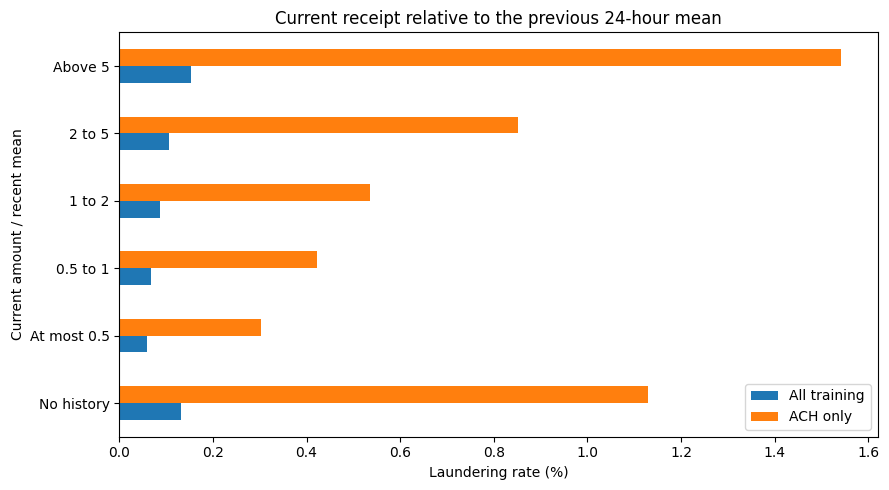

In [39]:
ratio_order = ["No history", "Zero mean", "At most 0.5", "0.5 to 1", "1 to 2", "2 to 5", "Above 5"]
ratio_records = history.withColumn(
    "ratio_band", F.when(F.col("receiver_previous_24h") == 0, ratio_order[0])
    .when(F.col("receiver_mean_24h") == 0, ratio_order[1])
    .when(F.col("receiver_amount_ratio") <= 0.5, ratio_order[2])
    .when(F.col("receiver_amount_ratio") <= 1, ratio_order[3])
    .when(F.col("receiver_amount_ratio") <= 2, ratio_order[4])
    .when(F.col("receiver_amount_ratio") <= 5, ratio_order[5]).otherwise(ratio_order[6])
)
ratio_summary = history_summary(ratio_records, "ratio_band", ratio_order)
display(ratio_summary.round(3))
plot_data = ratio_summary[["rate", "ach_rate"]].rename(columns={"rate": "All training", "ach_rate": "ACH only"})
plot_data.plot.barh(figsize=(9, 5))
plt.title("Current receipt relative to the previous 24-hour mean")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Current amount / recent mean")
plt.tight_layout()
plt.show()

Within ACH, receipts above five times the recent mean have a 1.543% rate, compared with 0.303% at or below half the mean. Across all formats, the rates are 0.153% and 0.059%.

A recent mean is available for only 51.66% of positives, so the model also needs a missing history flag. No zero means occur in this training data. The observed ratios are candidates to test, not fixed decision rules.

#### Features suggested by the analysis
Keep payment format, currencies and log amount because their relationships help explain the observed rates. Hour, weekday and bank relationships add context. Pair count, transaction gaps and relative receipts describe earlier account activity.

Use missing history flags alongside the measurements. Exclude labels, IDs, full dates and future information from the inputs. Validation will show whether the history features improve on the transaction fields alone.

In [40]:
eda_summaries = {
    "entity": entity_risk, "format": format_risk, "currency": currency_risk,
    "format_currency": format_currency_risk, "relative_amount": amount_risk,
    "hour": hour_risk, "date": day_risk, "bank": bank_risk,
    "currency_relationship": currency_change_risk, "relationship_joint": relationship_joint,
}
eda_evidence = {"scope": "training only", "training_rows": training_count,
                "training_positives": training_positives, "baseline_accuracy": baseline_accuracy,
                "summaries": {name: table.to_dict("records") for name, table in eda_summaries.items()}}
eda_evidence["additional_plots"] = {
    "amount_quantiles": amount_quantiles.assign(quantiles=amount_quantiles.quantiles.map(list)).to_dict("records"),
    "amount_bins": amount_bins.to_dict("records"),
    "paid_received": paired_amount_summary.to_dict("records"),
    "time_grid": time_grid.to_dict("records"),
    "amount_format": amount_format.to_dict("records"),
    "ach_middle": ach_middle.to_dict("records"),
}
eda_evidence["history_features"] = {
    "scope": "All training dates; strictly earlier training timestamps",
    "coverage": history_check.asDict(),
    "pair_counts": pair_summary.reset_index().to_dict("records"),
    "transaction_gaps": {name: table.reset_index().to_dict("records") for name, table in gap_summaries.items()},
    "receiver_amount_ratio": ratio_summary.reset_index().to_dict("records"),
    "amount_window": "Preceding 24 hours within receiver bank, account and receiving currency",
}
(PROJECT_ROOT / ".runtime/training_analysis.json").write_text(json.dumps(eda_evidence, indent=2) + "\n")

90382

### A4. Engineer features and build the pipeline

#### Prepare the feature tables
Each table has 16 candidate inputs, a source ID and the target. The ID and target stay outside the feature vector.

Format and currencies describe the payment. Log amount reduces skew while retaining zero amounts. Hour and weekday capture the timing patterns; Monday is 0 and Sunday is 6. The bank and currency indicators describe relationships between the two sides.

Pair count, sender and receiver gaps, recent receipt count and relative amount capture history. Missing gaps and ratios use zero placeholders with separate flags. A zero recent mean also sets the ratio flag. The mean itself is only used to calculate the ratio.

Raw IDs and entity names could encourage memorisation. Full dates could identify the sparse final period. Labels and label rates would reveal the answer. Entity type remains an optional comparison, while paid and received amounts duplicate each other for payments in the same currency.

In [41]:
def prepare_features(data):
    label_columns = ["is_laundering"] if "is_laundering" in data.columns else []
    return data.select(
        "source_record_id", "payment_format", "payment_currency", "receiving_currency",
        F.log1p("amount_paid").alias("log_amount_paid"),
        F.hour("timestamp").alias("hour"),
        ((F.dayofweek("timestamp") + 5) % 7).alias("weekday"),
        (F.col("from_bank") == F.col("to_bank")).cast("int").alias("same_bank"),
        (F.col("payment_currency") != F.col("receiving_currency")).cast("int").alias("currency_changed"),
        "prior_pair_count", "sender_gap_hours", "receiver_gap_hours",
        "receiver_previous_24h", "receiver_amount_ratio",
        F.col("sender_gap_hours").isNull().cast("int").alias("sender_history_missing"),
        F.col("receiver_gap_hours").isNull().cast("int").alias("receiver_history_missing"),
        F.col("receiver_amount_ratio").isNull().cast("int").alias("receiver_ratio_missing"),
        *label_columns,
    ).fillna(0, subset=["sender_gap_hours", "receiver_gap_hours", "receiver_amount_ratio"])

model_train_df = prepare_features(history)
feature_columns = [column for column in model_train_df.columns
                   if column not in ["source_record_id", "is_laundering"]]

#### Training table
Save the training table and display five rows in source ID order.

In [42]:
model_train_df.write.mode("overwrite").parquet(str(DATA_DIR / "model_training.parquet"))
model_train_df = spark.read.parquet(str(DATA_DIR / "model_training.parquet"))

print(f"Training rows: {model_train_df.count():,}")
print(f"Input features: {len(feature_columns)}")
model_head = model_train_df.orderBy("source_record_id").limit(5).toPandas()
display(model_head.round(4))

_ = history.unpersist()
_ = train_df.unpersist()

Training rows: 2,664,035
Input features: 16


,source_record_id,payment_format,payment_currency,receiving_currency,log_amount_paid,hour,weekday,same_bank,currency_changed,prior_pair_count,sender_gap_hours,receiver_gap_hours,receiver_previous_24h,receiver_amount_ratio,sender_history_missing,receiver_history_missing,receiver_ratio_missing,is_laundering
0,2,Cheque,US Dollar,US Dollar,0.0100,0,3,0,0,0,0.0,0.15,1,0.0001,1,0,0,0
1,5,Reinvestment,US Dollar,US Dollar,10.5101,0,3,1,0,0,0.0,0.00,0,0.0000,1,1,1,0
2,7,Reinvestment,US Dollar,US Dollar,2.7252,0,3,1,0,0,0.0,0.00,0,0.0000,1,1,1,0
3,8,Reinvestment,US Dollar,US Dollar,2.5541,0,3,1,0,0,0.0,0.00,0,0.0000,1,1,1,0
4,13,Credit Card,US Dollar,US Dollar,1.6114,0,3,0,0,0,0.0,0.00,0,0.0000,1,1,1,0


#### Validation and test history
Keep the existing partitions and class proportions. Each validation or test transaction uses only earlier training transactions as its reference history. Evaluation records never update that reference, and records at the same timestamp are excluded.

This keeps the history source fixed across both evaluation sets. It measures performance on new records with partial training history, not on a future time period. Streaming will need the same reference policy.

In [43]:
evaluation_history = add_history(development_df).filter(
    F.col("model_partition") != "train"
).persist(StorageLevel.MEMORY_AND_DISK)

model_validation_df = prepare_features(evaluation_history.filter(F.col("model_partition") == "validation"))
model_test_df = prepare_features(evaluation_history.filter(F.col("model_partition") == "test"))

model_validation_df.write.mode("overwrite").parquet(str(DATA_DIR / "model_validation.parquet"))
model_test_df.write.mode("overwrite").parquet(str(DATA_DIR / "model_test.parquet"))
model_validation_df = spark.read.parquet(str(DATA_DIR / "model_validation.parquet"))
model_test_df = spark.read.parquet(str(DATA_DIR / "model_test.parquet"))
_ = evaluation_history.unpersist()

#### Encode the categories
StringIndexer learns categories from training data. OneHotEncoder represents them as separate indicators, including an unknown category for new or missing values. Weekday is categorical so its numeric code does not imply a size or rank. Keeping every category makes the unknown indicator explicit.

VectorAssembler joins these indicators with the numeric inputs. Numeric values must be present and valid; missing history was handled before this step. No extra scaling is used here. Random forest does not need it, and Spark logistic regression can standardise internally.

In [44]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler

categorical_columns = ["payment_format", "payment_currency", "receiving_currency", "weekday"]
numeric_columns = [column for column in feature_columns if column not in categorical_columns]
index_columns = [column + "_index" for column in categorical_columns]
encoded_columns = [column + "_encoded" for column in categorical_columns]

indexer = StringIndexer(inputCols=categorical_columns, outputCols=index_columns, handleInvalid="keep")
encoder = OneHotEncoder(inputCols=index_columns, outputCols=encoded_columns, dropLast=False)
assembler = VectorAssembler(inputCols=numeric_columns + encoded_columns, outputCol="features")

preprocessor = Pipeline(stages=[indexer, encoder, assembler])
preprocessing_model = preprocessor.fit(model_train_df)

#### Apply the fitted pipeline
Use the same fitted stages for training, validation and test data. The saved preprocessing model can be reused without learning categories again. Model fitting and comparison follow in A5.

In [45]:
prepared_train_df = preprocessing_model.transform(model_train_df)
prepared_validation_df = preprocessing_model.transform(model_validation_df)
prepared_test_df = preprocessing_model.transform(model_test_df)
preprocessing_model.write().overwrite().save(str(DATA_DIR / "preprocessing_model"))

vector_size = prepared_train_df.schema["features"].metadata["ml_attr"]["num_attrs"]
summary = pd.DataFrame({
    "Rows": [model_train_df.count(), model_validation_df.count(), model_test_df.count()],
    "Input columns": len(feature_columns),
    "Vector values": vector_size,
}, index=["Training", "Validation", "Test"])
display(summary)

prepared_train_df.orderBy("source_record_id").select(
    "source_record_id", "features", "is_laundering"
).show(5, truncate=100)

,Rows,Input columns,Vector values
Training,2664035,16,60
Validation,572159,16,60
Test,572457,16,60


+----------------+----------------------------------------------------------------------------------------------------+-------------+
|source_record_id|                                                                                            features|is_laundering|
+----------------+----------------------------------------------------------------------------------------------------+-------------+
|               2|(60,[0,6,7,8,9,12,20,36,52],[0.009950330853168083,0.15,1.0,7.08918190840777E-5,1.0,1.0,1.0,1.0,1.0])|            0|
|               5|                 (60,[0,2,9,10,11,16,20,36,52],[10.510095153883276,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])|            0|
|               7|                  (60,[0,2,9,10,11,16,20,36,52],[2.725235025856311,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])|            0|
|               8|                  (60,[0,2,9,10,11,16,20,36,52],[2.554121718809473,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])|            0|
|              13|                       (60,[0,9,10,11,13,20,

#### Transform without the label
The preprocessing stages use only the selected inputs. The same records can be transformed when the target label is absent.

In [46]:
unlabelled_sample = model_validation_df.orderBy("source_record_id").limit(5).drop("is_laundering")
preprocessing_model.transform(unlabelled_sample).select("source_record_id", "features").show(5, truncate=100)

+----------------+-----------------------------------------------------------------------------------+
|source_record_id|                                                                           features|
+----------------+-----------------------------------------------------------------------------------+
|               6| (60,[0,2,9,10,11,16,20,36,52],[8.726390342215547,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])|
|              12| (60,[0,2,9,10,11,16,20,36,52],[2.339880877737743,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])|
|              28| (60,[0,2,9,10,11,16,20,36,52],[6.619566411464762,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])|
|              31| (60,[0,2,9,10,11,16,20,36,52],[6.864252611332742,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])|
|              38|(60,[0,2,9,10,11,16,20,36,52],[12.166059802725023,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])|
+----------------+-----------------------------------------------------------------------------------+



### A5. Train and compare models

### A6. Save and reload the selected pipeline

## Part B: Real time streaming
### B1. Kafka producer and message schema

### B2. Read, parse and predict

### B3. Sliding windows, watermark and outputs

### B4. Run the complete stream

### Reflection

### Stop Spark
Run this cell when finished. Start Spark again before continuing with more processing.

In [47]:
for query in spark.streams.active:
    query.stop()
spark.stop()
print("Spark session stopped.")

Spark session stopped.
